# 💳 Fraud Detection in Financial Transactions

This project focuses on building a machine learning-based fraud detection system for financial transactions. The goal is to accurately classify transactions as legitimate or fraudulent by analyzing various transaction features. The system helps financial institutions reduce fraud, prevent monetary losses, and enhance customer trust through timely and reliable fraud detection.

## Project Objectives

The primary objectives of this project are:

- To develop a machine learning model capable of detecting fraudulent financial transactions using transaction data.
- To analyze transaction patterns and identify key factors associated with fraudulent activities.
- To perform data preprocessing and exploratory data analysis (EDA) to gain meaningful insights from the dataset.
- To compare different machine learning algorithms and select the best-performing model for fraud detection.
- To evaluate the model using appropriate classification metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- To build a simple and user-friendly application that predicts whether a financial transaction is legitimate or fraudulent.
- To demonstrate how machine learning can help financial institutions detect fraud in real time, reduce financial losses, and improve the security of digital payment systems.

## Dataset Overview

The dataset used in this project is the **Credit Card Fraud Detection** dataset. It contains **284,807 financial transaction records** and **31 attributes**, where each row represents a single credit card transaction.

The dataset includes **28 anonymized numerical features (V1–V28)** generated using Principal Component Analysis (PCA), along with two additional features:
- **Time** – Time elapsed (in seconds) between the transaction and the first transaction in the dataset.
- **Amount** – The monetary value of the transaction.

The target variable is **Class**, where:
- **0** indicates a legitimate (non-fraudulent) transaction.
- **1** indicates a fraudulent transaction.

The dataset is highly imbalanced, with fraudulent transactions representing only a very small percentage of the total records. This makes fraud detection a challenging classification problem and an excellent dataset for developing and evaluating machine learning models for financial fraud detection.

## Dataset Highlights

- **Dataset Name:** Credit Card Fraud Detection Dataset
- **Domain:** Financial Fraud Detection
- **Dataset Type:** Binary Classification
- **Number of Records:** 284,807
- **Number of Features:** 31 (30 input features + 1 target variable)
- **Target Variable:** Class
- **Target Classes:** 0 (Legitimate Transaction), 1 (Fraudulent Transaction)
- **Key Features:** Time, Amount, and 28 anonymized PCA features (V1–V28)
- **Data Source:** Kaggle

##  Load the Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import kagglehub
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Dataset Path:", path)
df = pd.read_csv(path + "/creditcard.csv")
df

Dataset Path: C:\Users\arjun\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


### First 5 rows

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Last 5 rows

In [5]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


### Shape of the dataset

In [6]:
rows, columns = df.shape
print("Number of Rows:", rows)
print("Number of Columns:", columns)

Number of Rows: 284807
Number of Columns: 31


### Basic information

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

### Statistical Summary

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


### Columns

In [9]:
c = df.columns
for i  in c:
    print(i)

Time
V1
V2
V3
V4
V5
V6
V7
V8
V9
V10
V11
V12
V13
V14
V15
V16
V17
V18
V19
V20
V21
V22
V23
V24
V25
V26
V27
V28
Amount
Class


### Data Types of columns

In [10]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

##  Data Quality Assessment

Before performing exploratory data analysis and model development, it is essential to evaluate the quality of the dataset. This step involves checking for missing values, duplicate records, inconsistent data types, and unique values to ensure that the dataset is clean, complete, and suitable for machine learning.

###  Missing Values

In [11]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

- Observation

No missing values were found in the dataset. Therefore, the dataset is clean and ready for the next stage of data analysis and preprocessing.

###  Duplicate Records

In [12]:
df.duplicated().sum()

np.int64(1081)

- Observation

  Total Duplicate Records: 1,081

###  Unique Values

In [13]:
df.nunique()

Time      124592
V1        275663
V2        275663
V3        275663
V4        275663
V5        275663
V6        275663
V7        275663
V8        275663
V9        275663
V10       275663
V11       275663
V12       275663
V13       275663
V14       275663
V15       275663
V16       275663
V17       275663
V18       275663
V19       275663
V20       275663
V21       275663
V22       275663
V23       275663
V24       275663
V25       275663
V26       275663
V27       275663
V28       275663
Amount     32767
Class          2
dtype: int64

**Observation**

The unique value analysis shows that **Time** contains **124,592 unique values**, representing different transaction timestamps. The anonymized features **V1 to V28** contain **275,663 unique values**, indicating that they are continuous numerical features transformed using PCA and do not contain direct identifying information. The **Amount** feature has **32,767 unique values**, reflecting variations in transaction amounts. The target variable, **Class**, has **two unique classes (0 and 1)**, confirming that this is a **binary classification** problem.

###  Class Distribution (Target Variable)

In [14]:
val_no = df["Class"].value_counts()
val_per = df["Class"].value_counts(normalize=True) * 100

print('In numbers', val_no, '\n')
print("In percentage", val_per)

In numbers Class
0    284315
1       492
Name: count, dtype: int64 

In percentage Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


**Observation**

The target variable analysis shows that the **Class** feature contains two categories: **0 and 1**, representing legitimate and fraudulent transactions. The dataset is highly imbalanced, with **284,315 legitimate transactions (99.83%)** and only **492 fraudulent transactions (0.17%)**. This imbalance indicates that fraud detection is a challenging classification problem and requires appropriate evaluation metrics and handling techniques.

### Feature Classification

In [15]:
# Categorical (Object)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Binary Columns (0/1)
binary_cols = [col for col in df.columns if df[col].nunique() == 2]

# Continuous Numerical
continuous_cols = [col for col in df.select_dtypes(include=['number']).columns
                   if col not in binary_cols]

print("Categorical Columns:", categorical_cols)
print("\nContinuous Numerical Columns:", continuous_cols)
print("\nBinary Columns:", binary_cols)

Categorical Columns: []

Continuous Numerical Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Binary Columns: ['Class']


**Observation**

The feature type analysis shows that the dataset does not contain any categorical features. All input features are numerical in nature, including **Time**, **Amount**, and the anonymized features **V1 to V28**. The target variable **Class** is identified as a binary column with two unique values (**0 and 1**), representing legitimate and fraudulent transactions respectively. Since the dataset contains only numerical features, no categorical encoding is required before model training.

## Data Preprocessing

### Removing Unnecessary Columns

In this dataset, no unnecessary columns were removed because all features provide useful information for fraud detection. The dataset does not contain any identifier columns or irrelevant attributes. 

The features **V1 to V28**, **Time**, and **Amount** are retained as they may contribute to identifying fraudulent transaction patterns. The target variable **Class** is kept separately for classification.

In [16]:
# Removing Time column
df.drop("Time", axis=1, inplace=True)

# Display updated columns
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'],
      dtype='object')

# 📈 Exploratory Data Analysis (EDA)


## 📊 Univariate Analysis

Univariate Analysis focuses on examining one variable at a time. It helps understand the distribution, frequency, central tendency, spread, and characteristics of individual features without considering relationships with other variables.

### Distriburion analysis of 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'

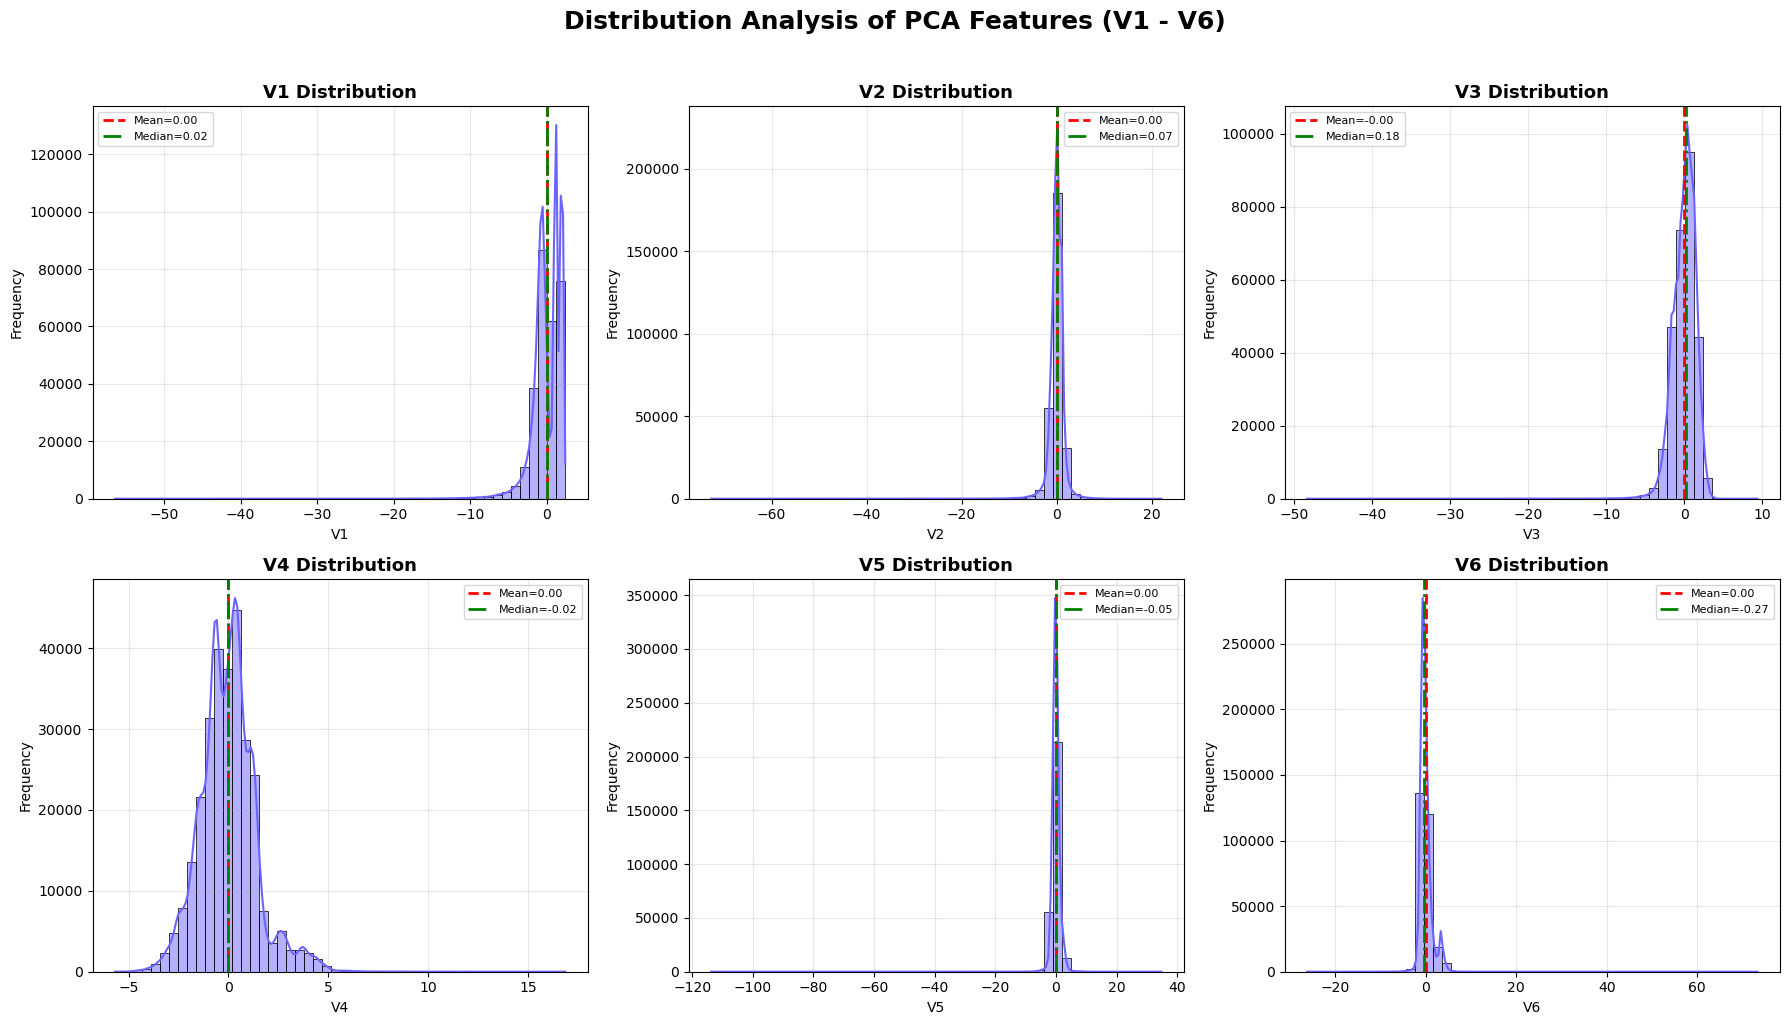

In [17]:
# Features
features = ['V1', 'V2', 'V3', 'V4', 'V5', 'V6']

# Create Canvas
plt.figure(figsize=(18, 10))

# Generate 6 plots
for i, feature in enumerate(features):
    
    # Calculate Mean & Median
    mean_val = df[feature].mean()
    median_val = df[feature].median()
    
    # Subplot
    plt.subplot(2, 3, i+1)
    
    # Histogram with KDE
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=50,
        color="#6C63FF",
        edgecolor="black"
    )
    
    # Mean Line
    plt.axvline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean={mean_val:.2f}"
    )
    
    # Median Line
    plt.axvline(
        median_val,
        color="green",
        linestyle="-.",
        linewidth=2,
        label=f"Median={median_val:.2f}"
    )
    
    # Styling
    plt.title(
        f"{feature} Distribution",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)

# Main Title
plt.suptitle(
    "Distribution Analysis of PCA Features (V1 - V6)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

Across all six PCA features ($V1$ through $V6$), the distributions exhibit zero-centered mean values around $0.00$ with medians remaining closely aligned near zero, indicating standard principal component scaling. While features like $V2$, $V3$, $V5$, and $V6$ present sharply leptokurtic peaks tightly packed near the origin, they show substantial heavy-tailed behavior, most prominently in $V5$ extending down near $-113$ and $V6$ stretching past $+73$. Features $V1$ and $V3$ demonstrate extreme left-skewness with values trailing down towards $-56$ and $-48$ respectively, whereas $V4$ displays a comparatively broader variance centered around its median of $-0.02$ with a distinct right-skewed tail reaching $+16.8$. Overall, the wide discrepancy between the concentrated central masses and the far-reaching tail extremes highlights significant anomaly presence across these components, necessitating robust scaling or non-linear tree-based architectures for downstream tasks.

### Distriburion analysis of 'V7', 'V8', 'V9', 'V10', 'V11', 'V12'

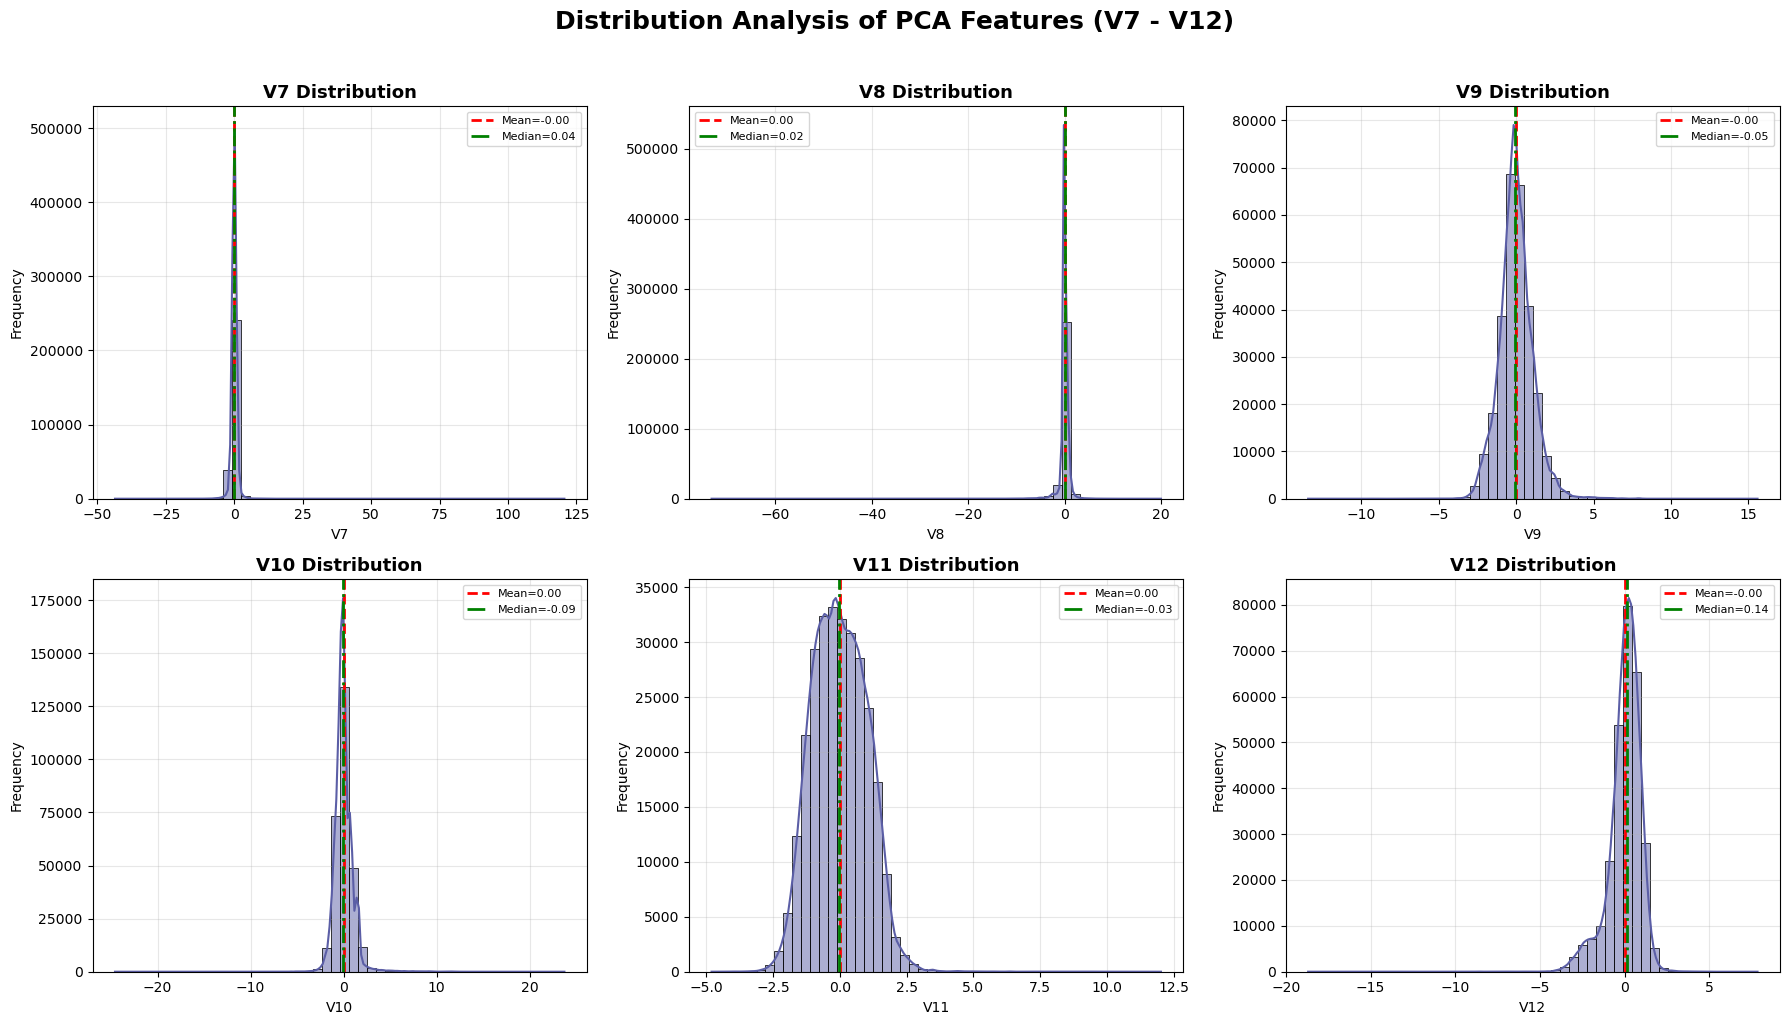

In [18]:
# Features
features = ['V7', 'V8', 'V9', 'V10', 'V11', 'V12']

# Create Canvas
plt.figure(figsize=(18, 10))

# Generate 6 plots
for i, feature in enumerate(features):
    
    # Calculate Mean & Median
    mean_val = df[feature].mean()
    median_val = df[feature].median()
    
    # Subplot
    plt.subplot(2, 3, i+1)
    
    # Histogram with KDE
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=50,
        color="#5B5EA6",
        edgecolor="black"
    )
    
    # Mean Line
    plt.axvline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean={mean_val:.2f}"
    )
    
    # Median Line
    plt.axvline(
        median_val,
        color="green",
        linestyle="-.",
        linewidth=2,
        label=f"Median={median_val:.2f}"
    )
    
    # Styling
    plt.title(
        f"{feature} Distribution",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)

# Main Title
plt.suptitle(
    "Distribution Analysis of PCA Features (V7 - V12)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The PCA features $V7$ through $V12$ reflect zero-centered distributions with mean values of $0.00$, though they exhibit contrasting structural behaviors across the set. While $V7$ and $V8$ feature extremely tall, sharp central peaks with massive single-direction outliers stretching beyond $+120$ and $-70$ respectively, $V11$ shows a much broader, near-Gaussian bell curve centered near its median of $-0.03$. Features $V9$ and $V10$ display fairly balanced, symmetrical distributions, whereas $V12$ demonstrates a pronounced left-skewed tail extending down to around $-18.6$. The wide variation between high-kurtosis spikes and long tail spreads across these components highlights significant extreme values in the dataset, requiring robust scaling or decision-tree models to manage feature variance during classification.

### Distriburion analysis of 'V13', 'V14', 'V15', 'V16', 'V17', 'V18'

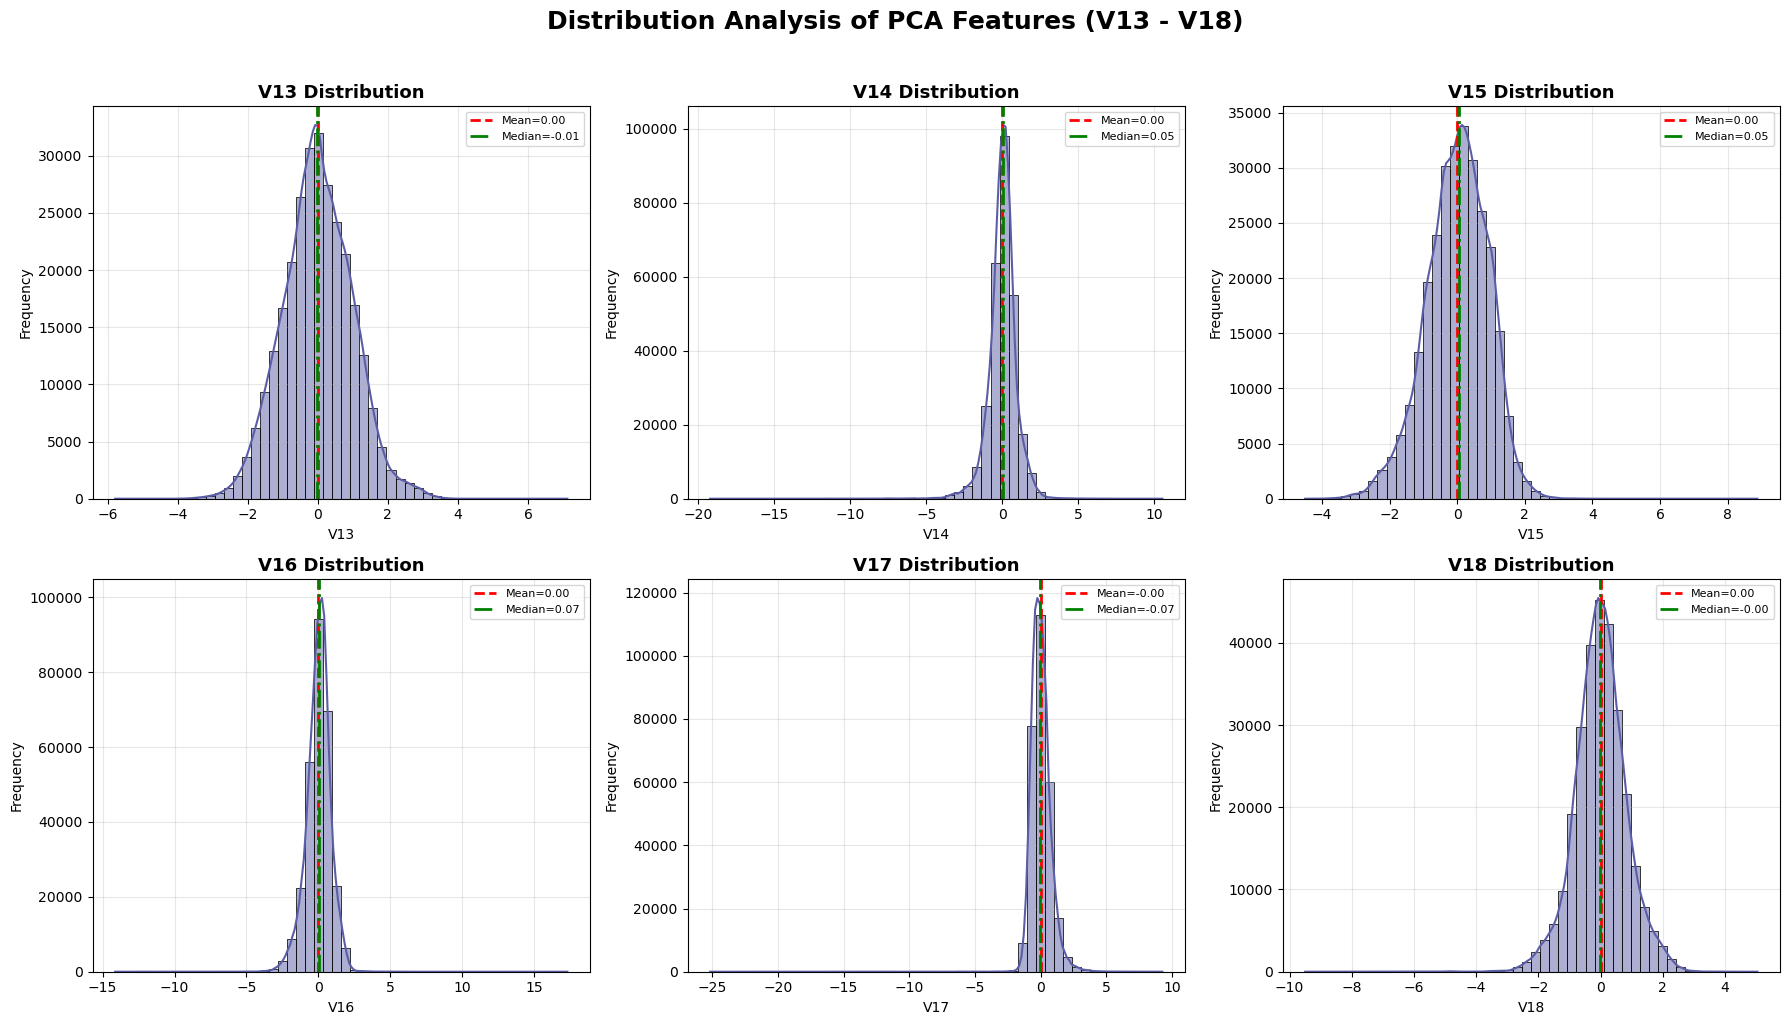

In [19]:
features = ['V13', 'V14', 'V15', 'V16', 'V17', 'V18']

# Create Canvas
plt.figure(figsize=(18, 10))

# Generate 6 plots
for i, feature in enumerate(features):
    
    # Calculate Mean & Median
    mean_val = df[feature].mean()
    median_val = df[feature].median()
    
    # Subplot
    plt.subplot(2, 3, i+1)
    
    # Histogram with KDE
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=50,
        color="#5B5EA6",
        edgecolor="black"
    )
    
    # Mean Line
    plt.axvline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean={mean_val:.2f}"
    )
    
    # Median Line
    plt.axvline(
        median_val,
        color="green",
        linestyle="-.",
        linewidth=2,
        label=f"Median={median_val:.2f}"
    )
    
    # Styling
    plt.title(
        f"{feature} Distribution",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)

# Main Title
plt.suptitle(
    "Distribution Analysis of PCA Features (V13 - V18)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The distributions for PCA features $V13$ through $V18$ remain centered around zero with means of $0.00$, though they show clear differences in spread and tail behavior. Features $V13$, $V15$, and $V18$ exhibit relatively smooth, bell-shaped curves with well-dispersed central masses, where $V13$ spans from roughly $-6$ to $+7$ and $V15$ reaches up to $+8.8$. In contrast, $V14$, $V16$, and $V17$ present much sharper central peaks with frequency counts exceeding $100,000$. These three features display heavy left-skewness, most notably in $V17$ and $V14$ where negative tails extend past $-25$ and $-19$ respectively. This combination of standard near-normal components and highly skewed, heavy-tailed variables highlights distinct behavioral patterns that will benefit from robust scaling prior to model fitting.

### Distribution analysis of 'V19', 'V20', 'V21', 'V22', 'V23', 'V24'

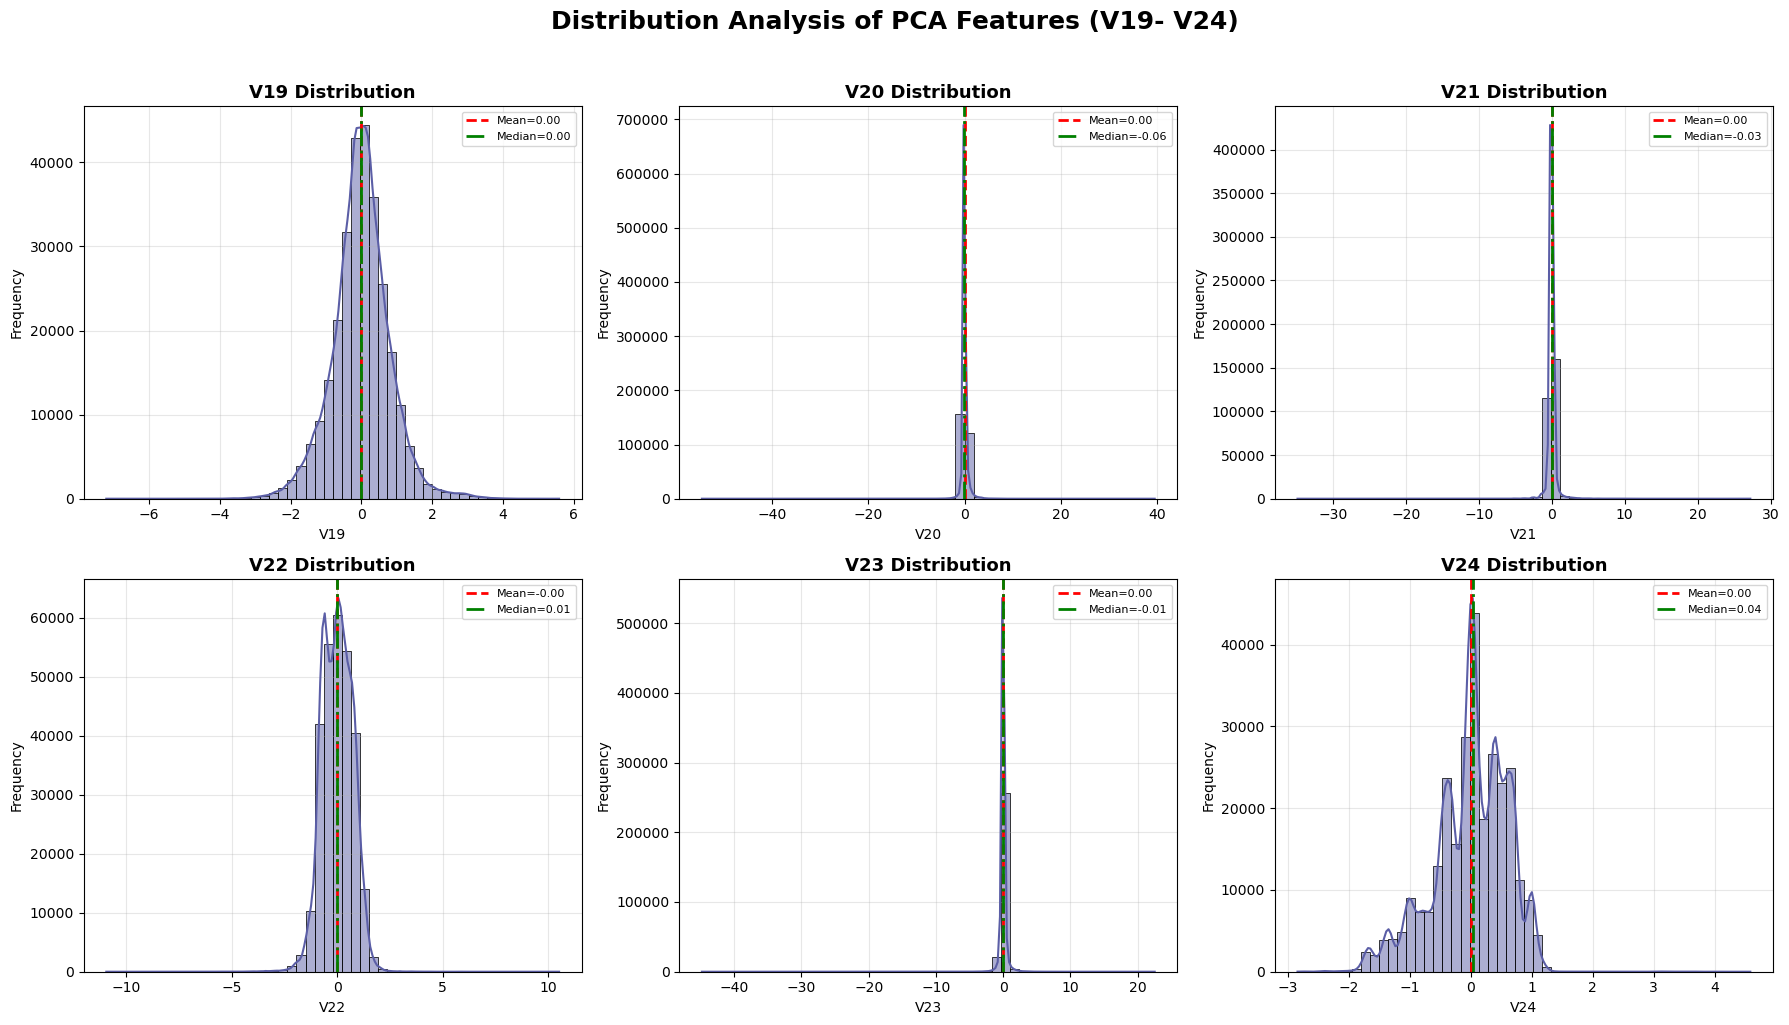

In [20]:
features = ['V19', 'V20', 'V21', 'V22', 'V23', 'V24']

# Create Canvas
plt.figure(figsize=(18, 10))

# Generate 6 plots
for i, feature in enumerate(features):
    
    # Calculate Mean & Median
    mean_val = df[feature].mean()
    median_val = df[feature].median()
    
    # Subplot
    plt.subplot(2, 3, i+1)
    
    # Histogram with KDE
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=50,
        color="#5B5EA6",
        edgecolor="black"
    )
    
    # Mean Line
    plt.axvline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean={mean_val:.2f}"
    )
    
    # Median Line
    plt.axvline(
        median_val,
        color="green",
        linestyle="-.",
        linewidth=2,
        label=f"Median={median_val:.2f}"
    )
    
    # Styling
    plt.title(
        f"{feature} Distribution",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)

# Main Title
plt.suptitle(
    "Distribution Analysis of PCA Features (V19- V24)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The distributions for PCA features $V19$ through $V24$ are all centered precisely near zero with mean values of $0.00$, but they reflect varying degrees of peakedness and tail dispersion. Features $V20$, $V21$, and $V23$ display extreme leptokurtic peaks reaching massive frequency counts up to $700,000$, with long heavy tails extending significantly in both directions, particularly $V20$ reaching past $-50$ and $+40$. In contrast, $V19$ and $V22$ exhibit more standard, near-Gaussian spreads centered around their respective medians of $0.00$ and $0.01$. $V24$ presents a unique multi-modal structure with distinct secondary crests along its left flank down to $-2.8$, before tapering off into a slight right tail past $+4$. These varied distribution profiles underscore the structural differences across the higher-order PCA components, indicating that appropriate scaling or tree-based modeling will be necessary to handle both the extreme outliers and complex feature shapes.

### Distribution analysis of 'V25', 'V26', 'V27', 'V28'

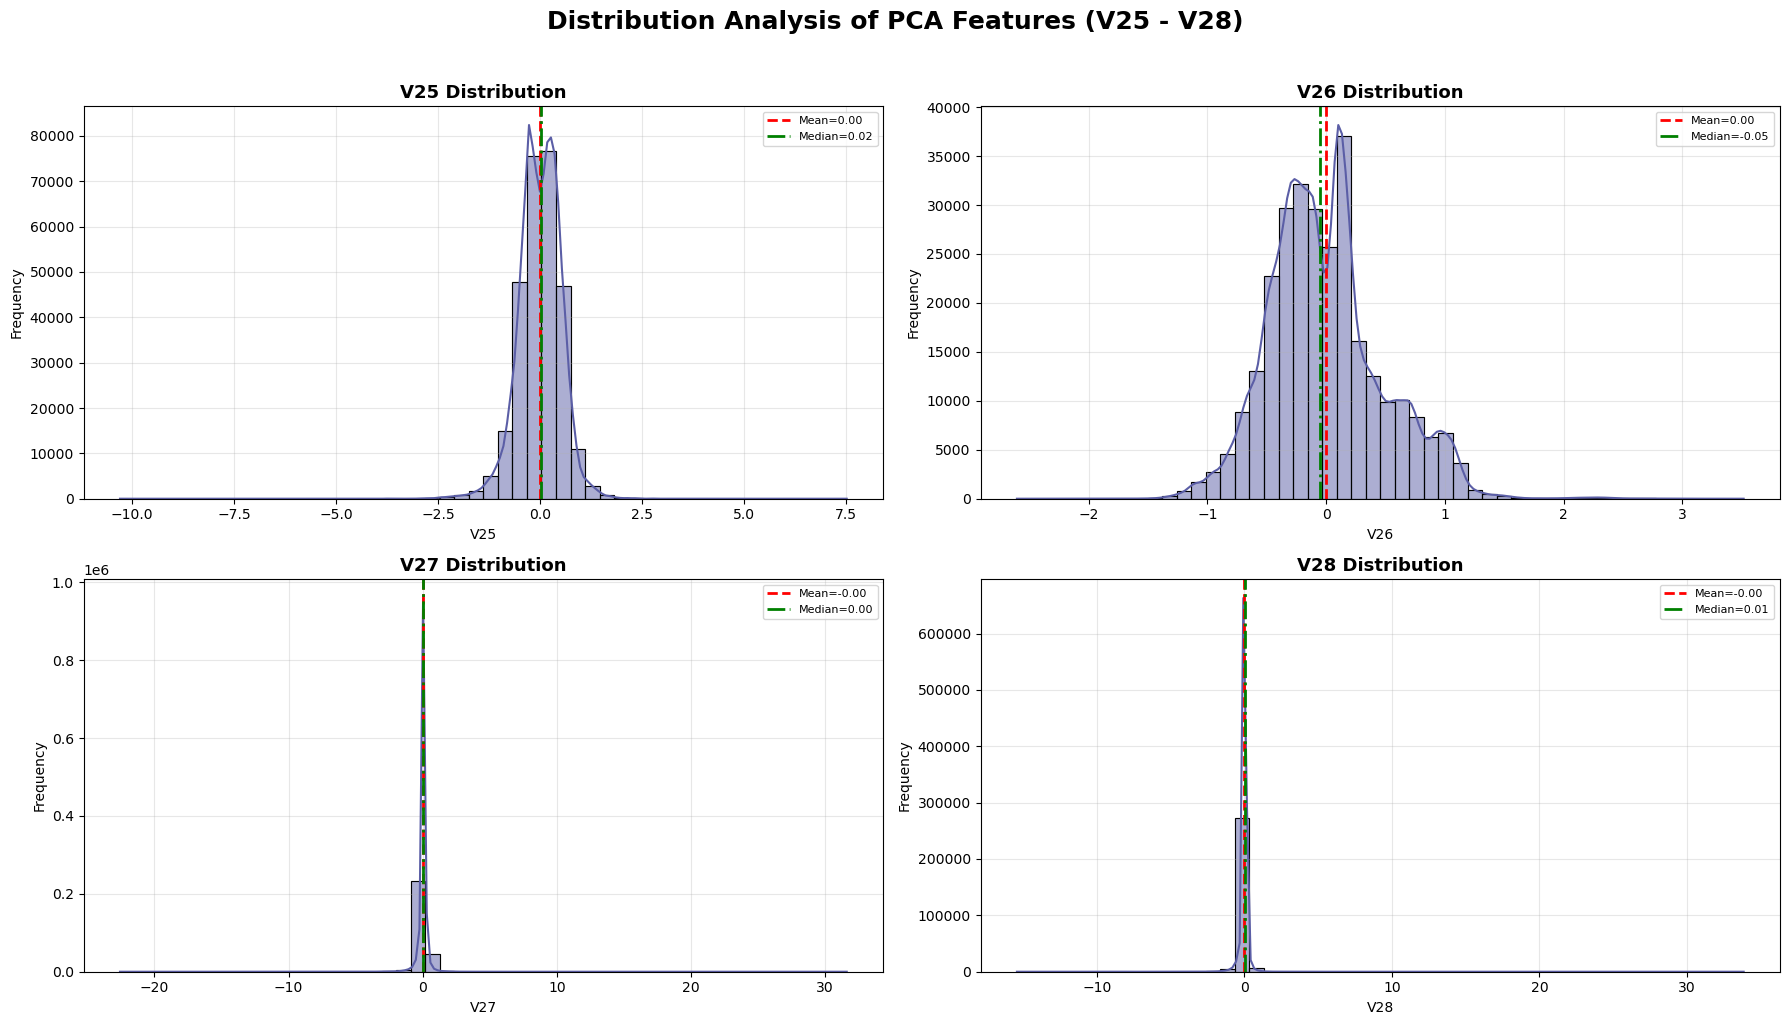

In [21]:
features = ['V25', 'V26', 'V27', 'V28']

# Create Canvas
plt.figure(figsize=(18, 10))

# Generate 6 plots
for i, feature in enumerate(features):
    
    # Calculate Mean & Median
    mean_val = df[feature].mean()
    median_val = df[feature].median()
    
    # Subplot
    plt.subplot(2, 2, i+1)
    
    # Histogram with KDE
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=50,
        color="#5B5EA6",
        edgecolor="black"
    )
    
    # Mean Line
    plt.axvline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean={mean_val:.2f}"
    )
    
    # Median Line
    plt.axvline(
        median_val,
        color="green",
        linestyle="-.",
        linewidth=2,
        label=f"Median={median_val:.2f}"
    )
    
    # Styling
    plt.title(
        f"{feature} Distribution",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)

# Main Title
plt.suptitle(
    "Distribution Analysis of PCA Features (V25 - V28)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The distributions for PCA features $V25$ through $V28$ all maintain zero-centered means of $0.00$, but present sharply contrasting structural properties and tail dynamics. $V27$ and $V28$ exhibit extreme leptokurtic behavior with massive central peaks reaching frequency counts near $1,000,000$ and $650,000$ respectively, accompanied by heavy tails stretching beyond $-22$ to $+31$ for $V27$ and $-15$ to $+33$ for $V28$. Conversely, $V25$ demonstrates a narrower central mass centered at its median of $0.02$ with an extended negative tail down to $-10.2$, while $V26$ displays a unique bimodal/multi-crested shape spanning mostly between $-1.5$ and $+1.5$. These final components highlight a blend of multimodal shapes and extreme outlier spreads, reinforcing the need for non-linear models or robust scaling across the entire PCA feature set.

### Amount Distribution analysis

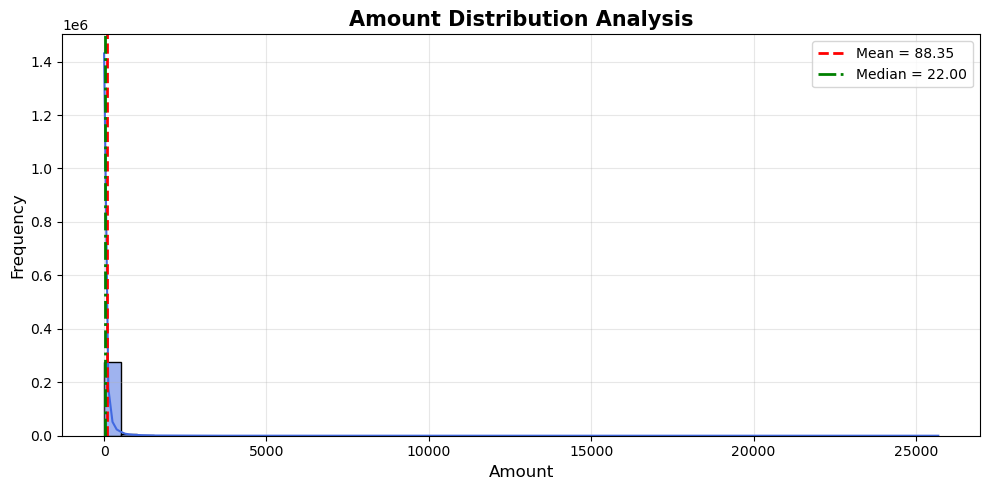

In [22]:
# Feature
feature = "Amount"

# Calculate Mean & Median
mean_val = df[feature].mean()
median_val = df[feature].median()

# Figure
plt.figure(figsize=(10,5))

# Histogram with KDE
sns.histplot(
    data=df,
    x=feature,
    bins=50,
    kde=True,
    color="royalblue",
    edgecolor="black"
)

# Mean Line
plt.axvline(
    mean_val,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_val:.2f}"
)

# Median Line
plt.axvline(
    median_val,
    color="green",
    linestyle="-.",
    linewidth=2,
    label=f"Median = {median_val:.2f}"
)

# Styling
plt.title(
    "Amount Distribution Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Amount", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

**Observation**

The `Amount` feature exhibits an extreme right-skewed (positively skewed) distribution, with an overwhelming majority of transactions concentrated near zero. The median transaction value sits at $22.00$, while the mean is substantially higher at $88.35$, directly pulled upward by sparse, high-value transactions. While most volume stays well under $500$, the long right tail stretches continuously up to a maximum near $25,691$.

### Class Distribution analysis

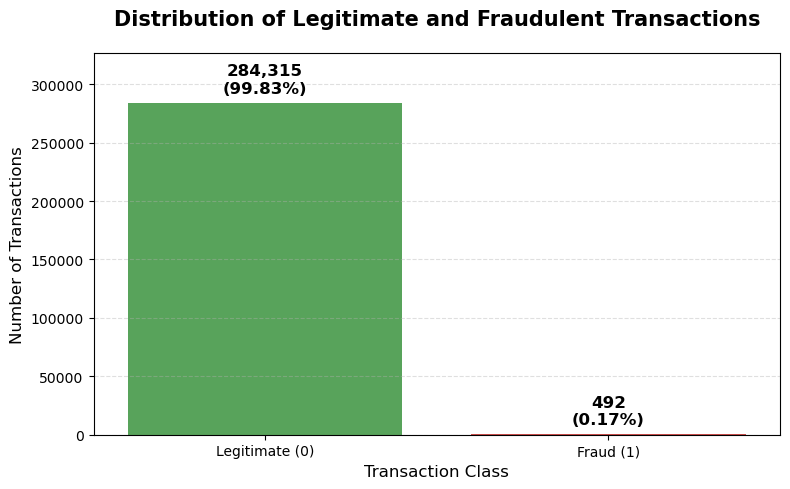

In [23]:
# Class counts
class_counts = df["Class"].value_counts()

# Percentage calculation
class_percent = df["Class"].value_counts(normalize=True) * 100

# Create figure
plt.figure(figsize=(8,5))

# Custom colors
colors = ["#4CAF50", "#E53935"]

# Bar plot
ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=colors,
    legend=False
)

# Add space for annotations
plt.ylim(0, class_counts.max() * 1.15)

# Add annotations
for i, count in enumerate(class_counts.values):
    percentage = class_percent.iloc[i]
    
    ax.text(
        i,
        count + class_counts.max()*0.03,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Title
plt.title(
    "Distribution of Legitimate and Fraudulent Transactions",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Labels
plt.xlabel("Transaction Class", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)

plt.xticks(
    [0,1],
    ["Legitimate (0)", "Fraud (1)"]
)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

**Observation**

The dataset exhibits extreme class imbalance between transaction types. Legitimate transactions (Class 0) make up the overwhelming majority at **284,315** instances (**99.83%**), whereas Fraudulent transactions (Class 1) account for only **492** instances (**0.17%**). This severe imbalance means standard accuracy will be a highly misleading evaluation metric, as a naive model predicting all transactions as legitimate would achieve 99.83% accuracy while missing every fraudulent case.

## Bivariate Analysis: 

### V1, V2, V3, V4, V5,V6 vs Class Analysis

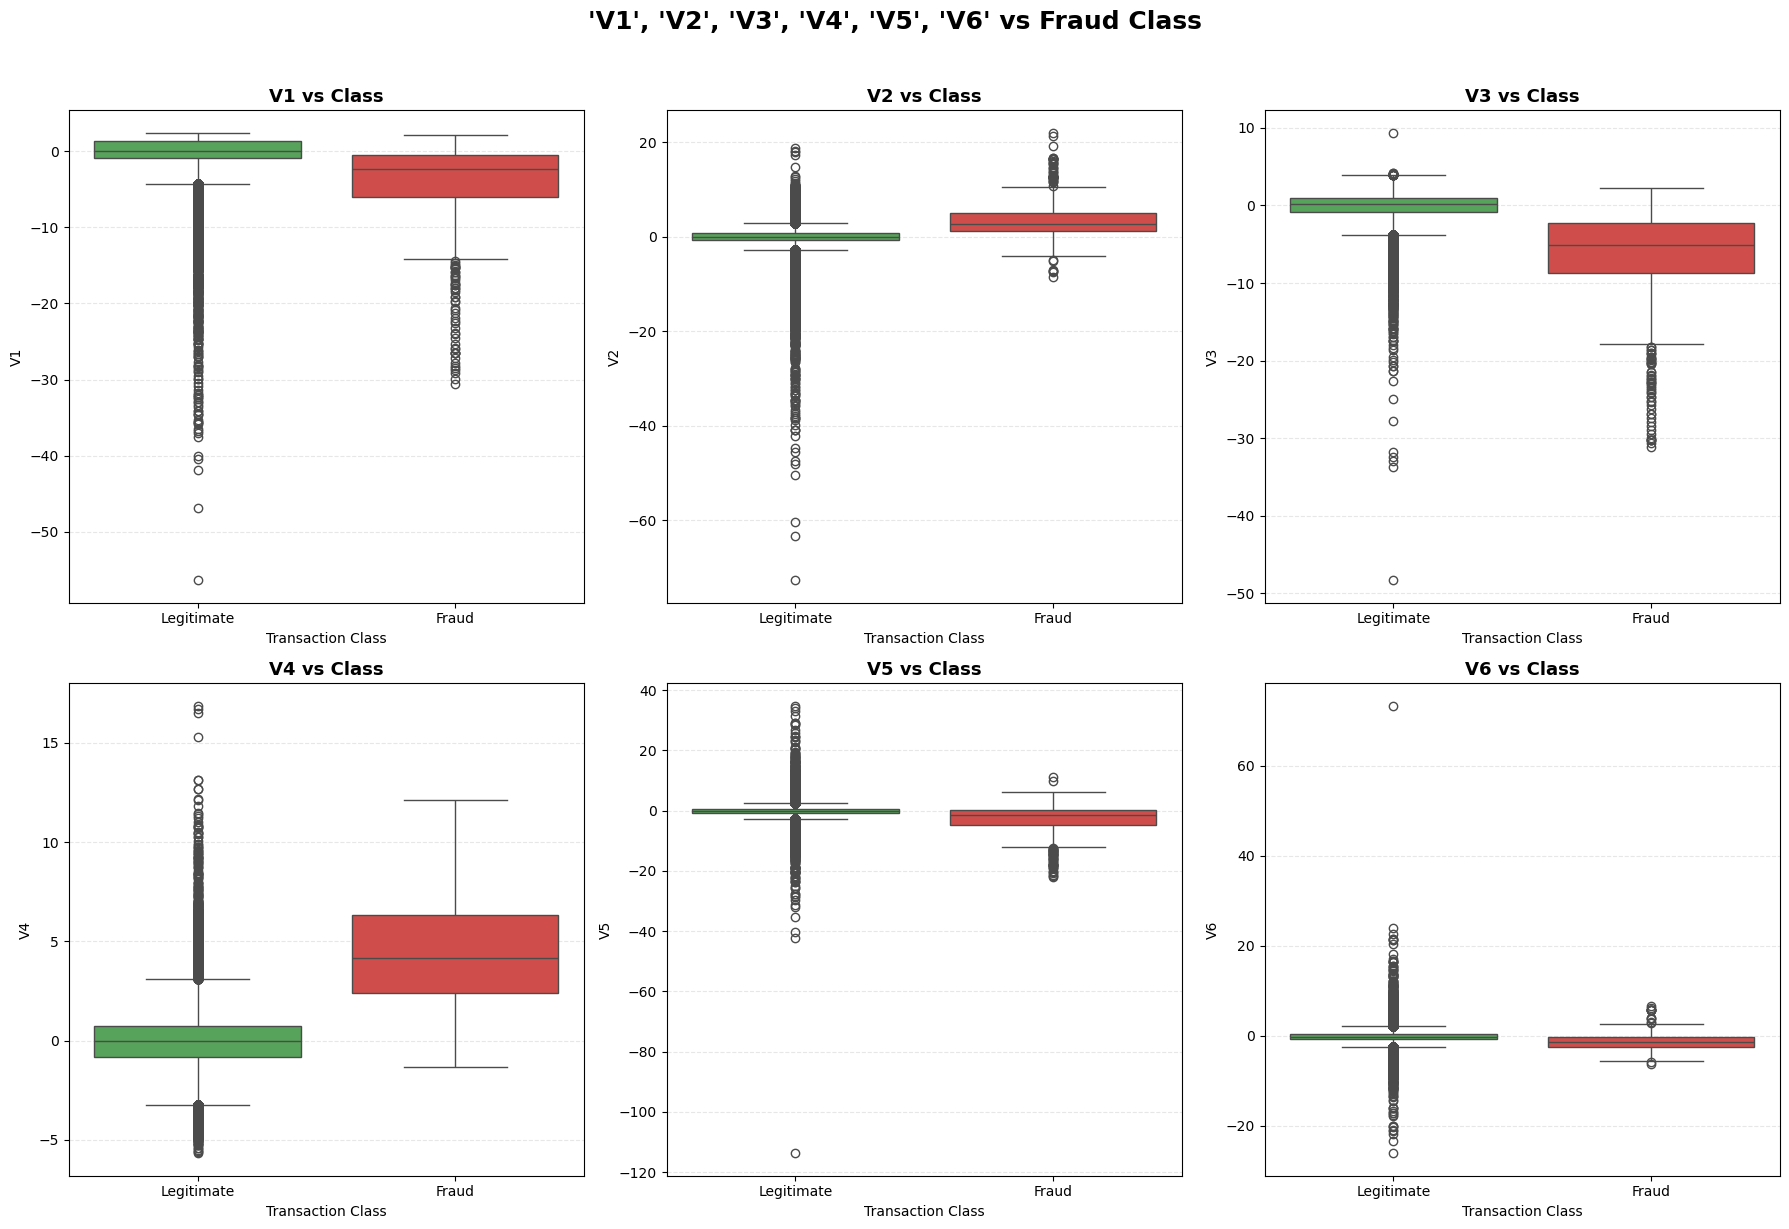

In [24]:
# Features for bivariate analysis
features = ['V1', 'V2', 'V3', 'V4', 'V5', 'V6']

# Create canvas
plt.figure(figsize=(18, 12))

for i, feature in enumerate(features):
    
    plt.subplot(2, 3, i+1)
    
    # Boxplot with Class
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        palette=["#4CAF50", "#E53935"],
        legend=False
    )
    
    # Title
    plt.title(
        f"{feature} vs Class",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(
        "Transaction Class"
    )
    
    plt.ylabel(
        feature
    )
    
    plt.xticks(
        [0,1],
        ["Legitimate", "Fraud"]
    )
    
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

# Main title
plt.suptitle(
    "'V1', 'V2', 'V3', 'V4', 'V5', 'V6' vs Fraud Class",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The box plots illustrate the class-conditional distributions of PCA features $V1$ through $V6$ across **Legitimate** (green) and **Fraud** (red) transaction classes, revealing strong linear separation capabilities for several components:

* **Inverse Relationship ($V1, V3, V5, V6$):** Fraudulent transactions systematically shift toward lower values compared to legitimate transactions. This separation is most pronounced in **$V1$** and **$V3$**, where the interquartile ranges (IQRs) for Fraud sit distinctly below those of Legitimate cases, making them powerful discriminative signals.
* **Direct Relationship ($V2, V4$):** Fraudulent transactions shift toward higher values relative to legitimate ones. **$V4$** displays exceptional class separation, with its Fraud IQR ($+2.5$ to $+6.3$) almost entirely decoupled from the Legitimate baseline centered near zero. **$V2$** also reflects a clear upward shift in median for fraudulent cases.

### 'V7', 'V8', 'V9', 'V10', 'V11', 'V12' VS Class Analysis

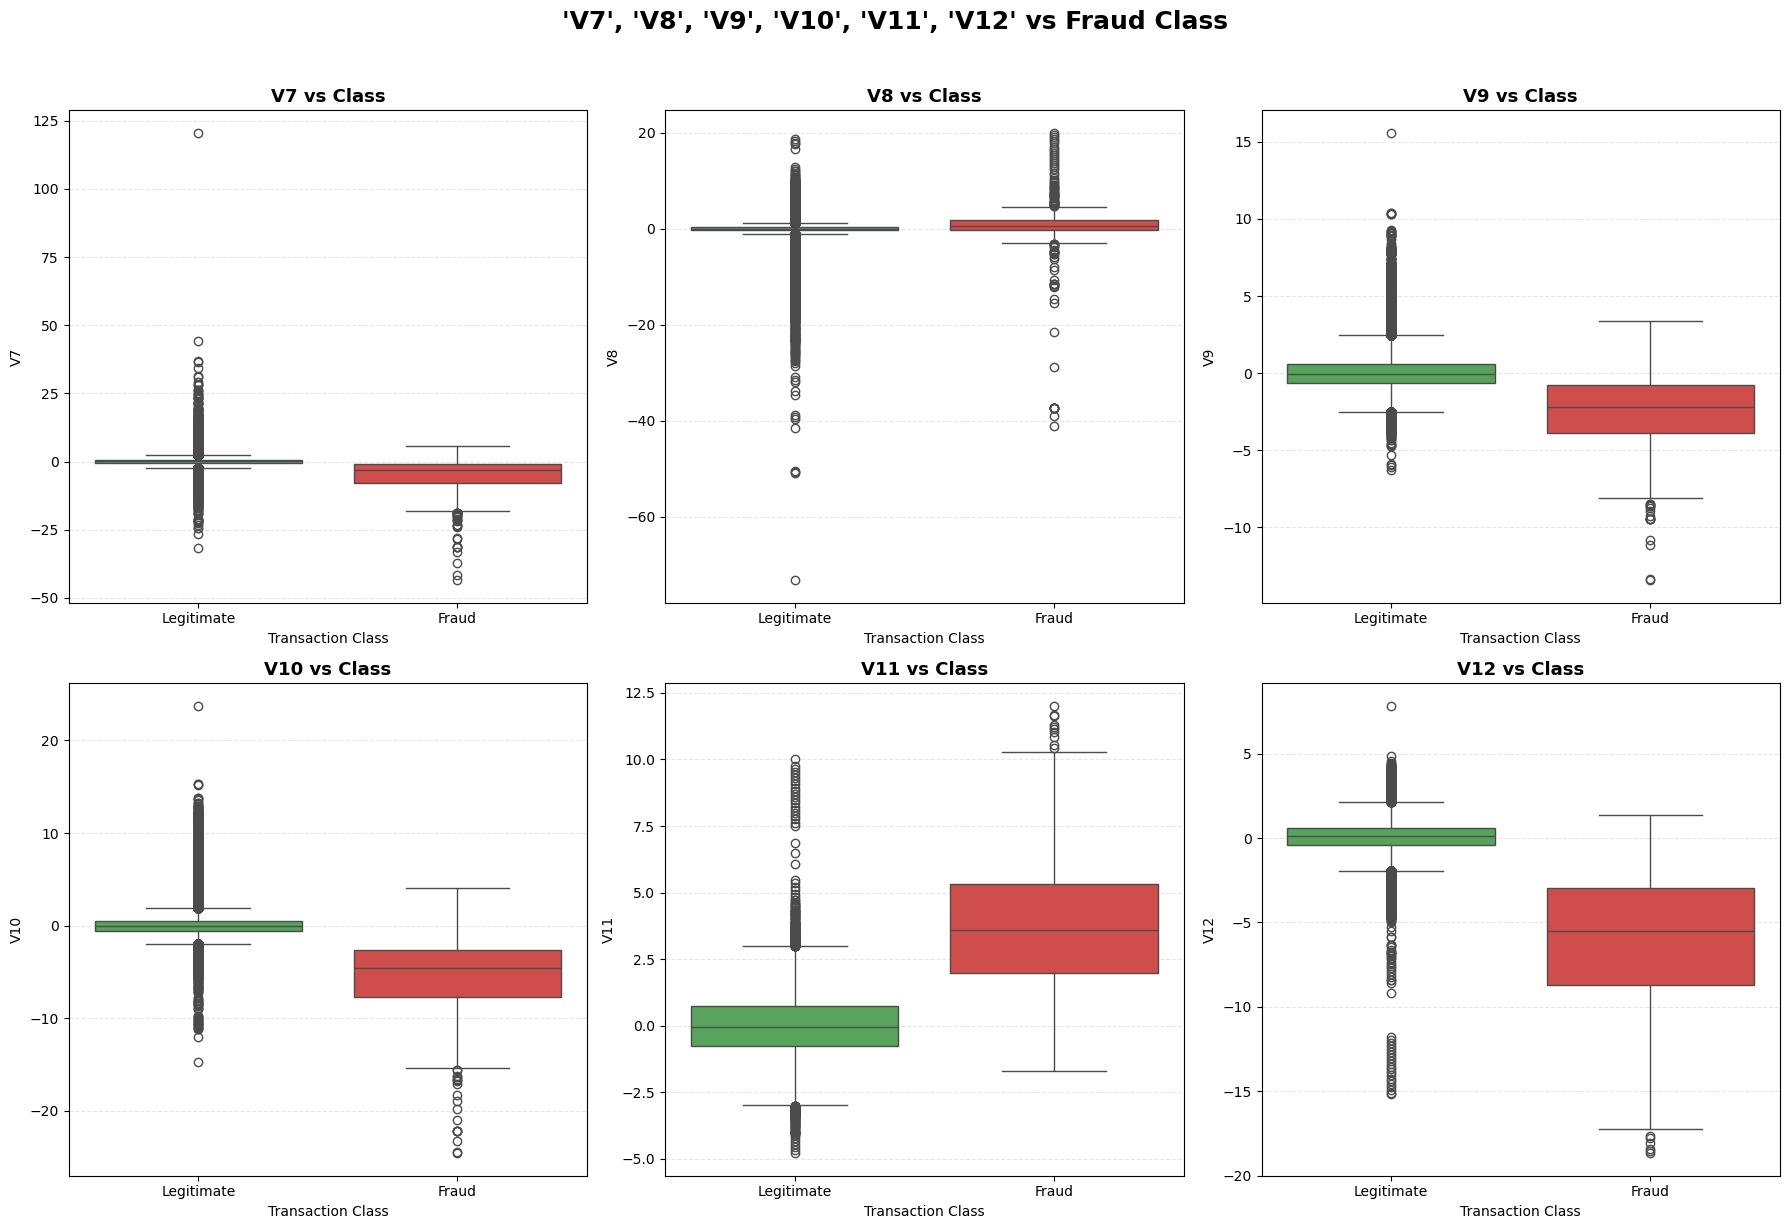

In [25]:
features = ['V7', 'V8', 'V9', 'V10', 'V11', 'V12']

# Create canvas
plt.figure(figsize=(18, 12))

for i, feature in enumerate(features):
    
    plt.subplot(2, 3, i+1)
    
    # Boxplot with Class
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        palette=["#4CAF50", "#E53935"],
        legend=False
    )
    
    # Title
    plt.title(
        f"{feature} vs Class",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(
        "Transaction Class"
    )
    
    plt.ylabel(
        feature
    )
    
    plt.xticks(
        [0,1],
        ["Legitimate", "Fraud"]
    )
    
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

# Main title
plt.suptitle(
    "'V7', 'V8', 'V9', 'V10', 'V11', 'V12' vs Fraud Class",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The box plots display the distribution of PCA features $V7$ through $V12$ conditional on the transaction class (**Legitimate** in green vs. **Fraud** in red), highlighting several high-importance predictors with strong class separation:

* **Strong Inverse Relationship ($V7, V9, V10, V12$):** Fraudulent transactions show significant downward shifts compared to legitimate ones. This separation is particularly pronounced in **$V10$** and **$V12$**, where the Interquartile Ranges (IQRs) for Fraud sit almost entirely below the Legitimate baseline centered near zero. **$V7$** and **$V9$** also exhibit clear negative shifts in median for fraudulent cases.
* **Direct Relationship ($V11$):** **$V11$** demonstrates exceptional direct separation power, with Fraud values shifting strongly upward into positive territory (IQR spanning roughly $+2.0$ to $+5.3$) compared to Legitimate transactions centered near zero.
* **Weak Discrimination ($V8$):** **$V8$** exhibits nearly identical median values near zero for both classes, though Fraud cases present a slightly broader interquartile spread and elevated upper outliers, indicating lower standalone linear predictive strength relative to $V10, V11$, or $V12$.

### 'V13', 'V14', 'V15', 'V16', 'V17', 'V18' vs Class analysis

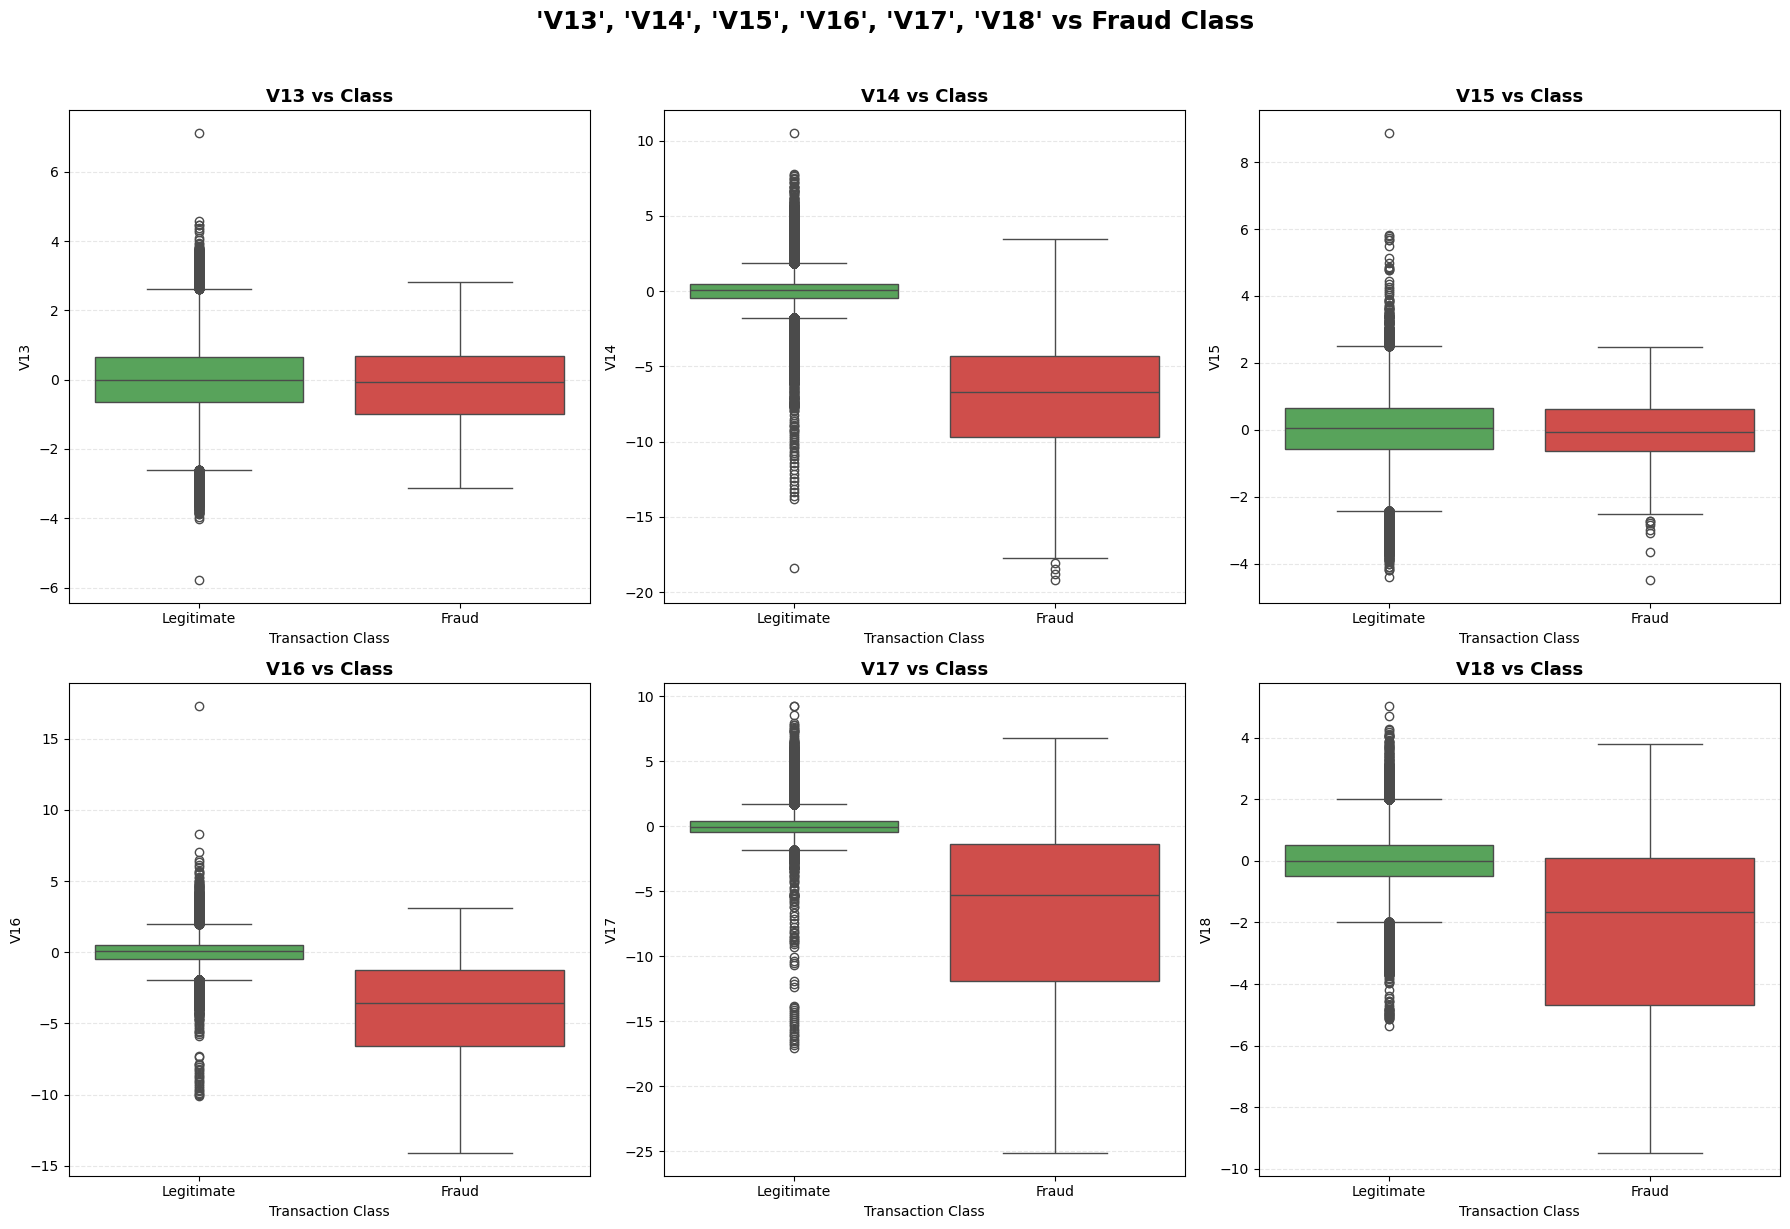

In [26]:
features = ['V13', 'V14', 'V15', 'V16', 'V17', 'V18']

# Create canvas
plt.figure(figsize=(18, 12))

for i, feature in enumerate(features):
    
    plt.subplot(2, 3, i+1)
    
    # Boxplot with Class
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        palette=["#4CAF50", "#E53935"],
        legend=False
    )
    
    # Title
    plt.title(
        f"{feature} vs Class",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(
        "Transaction Class"
    )
    
    plt.ylabel(
        feature
    )
    
    plt.xticks(
        [0,1],
        ["Legitimate", "Fraud"]
    )
    
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

# Main title
plt.suptitle(
    "'V13', 'V14', 'V15', 'V16', 'V17', 'V18' vs Fraud Class",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The box plots examine the class-conditional distributions of PCA features $V13$ through $V18$ across **Legitimate** (green) and **Fraud** (red) transactions, revealing key discriminative features alongside uninformative components:

* **Primary Discriminative Signals ($V14, V16, V17, V18$):** All four features exhibit massive negative drops for Fraud cases relative to Legitimate transactions.
* **$V14$ & $V17$** act as top-tier predictors, with Fraud IQRs shifting significantly lower (spanning $-9.6$ to $-4.4$ for $V14$, and $-12.0$ to $-1.4$ for $V17$) compared to Legitimate baselines tightly bound near zero.
* **$V16$ & $V18$** show similar strong negative shifts, with Fraud medians falling below $-3.5$ and $-1.6$ respectively.


* **Low Separation Features ($V13, V15$):** Both **$V13$** and **$V15$** display almost completely overlapping box plots and medians near zero across both classes, indicating negligible standalone linear separation capacity for fraud detection.

### 'V19', 'V20', 'V21', 'V22', 'V23', 'V24' vs Class analysis

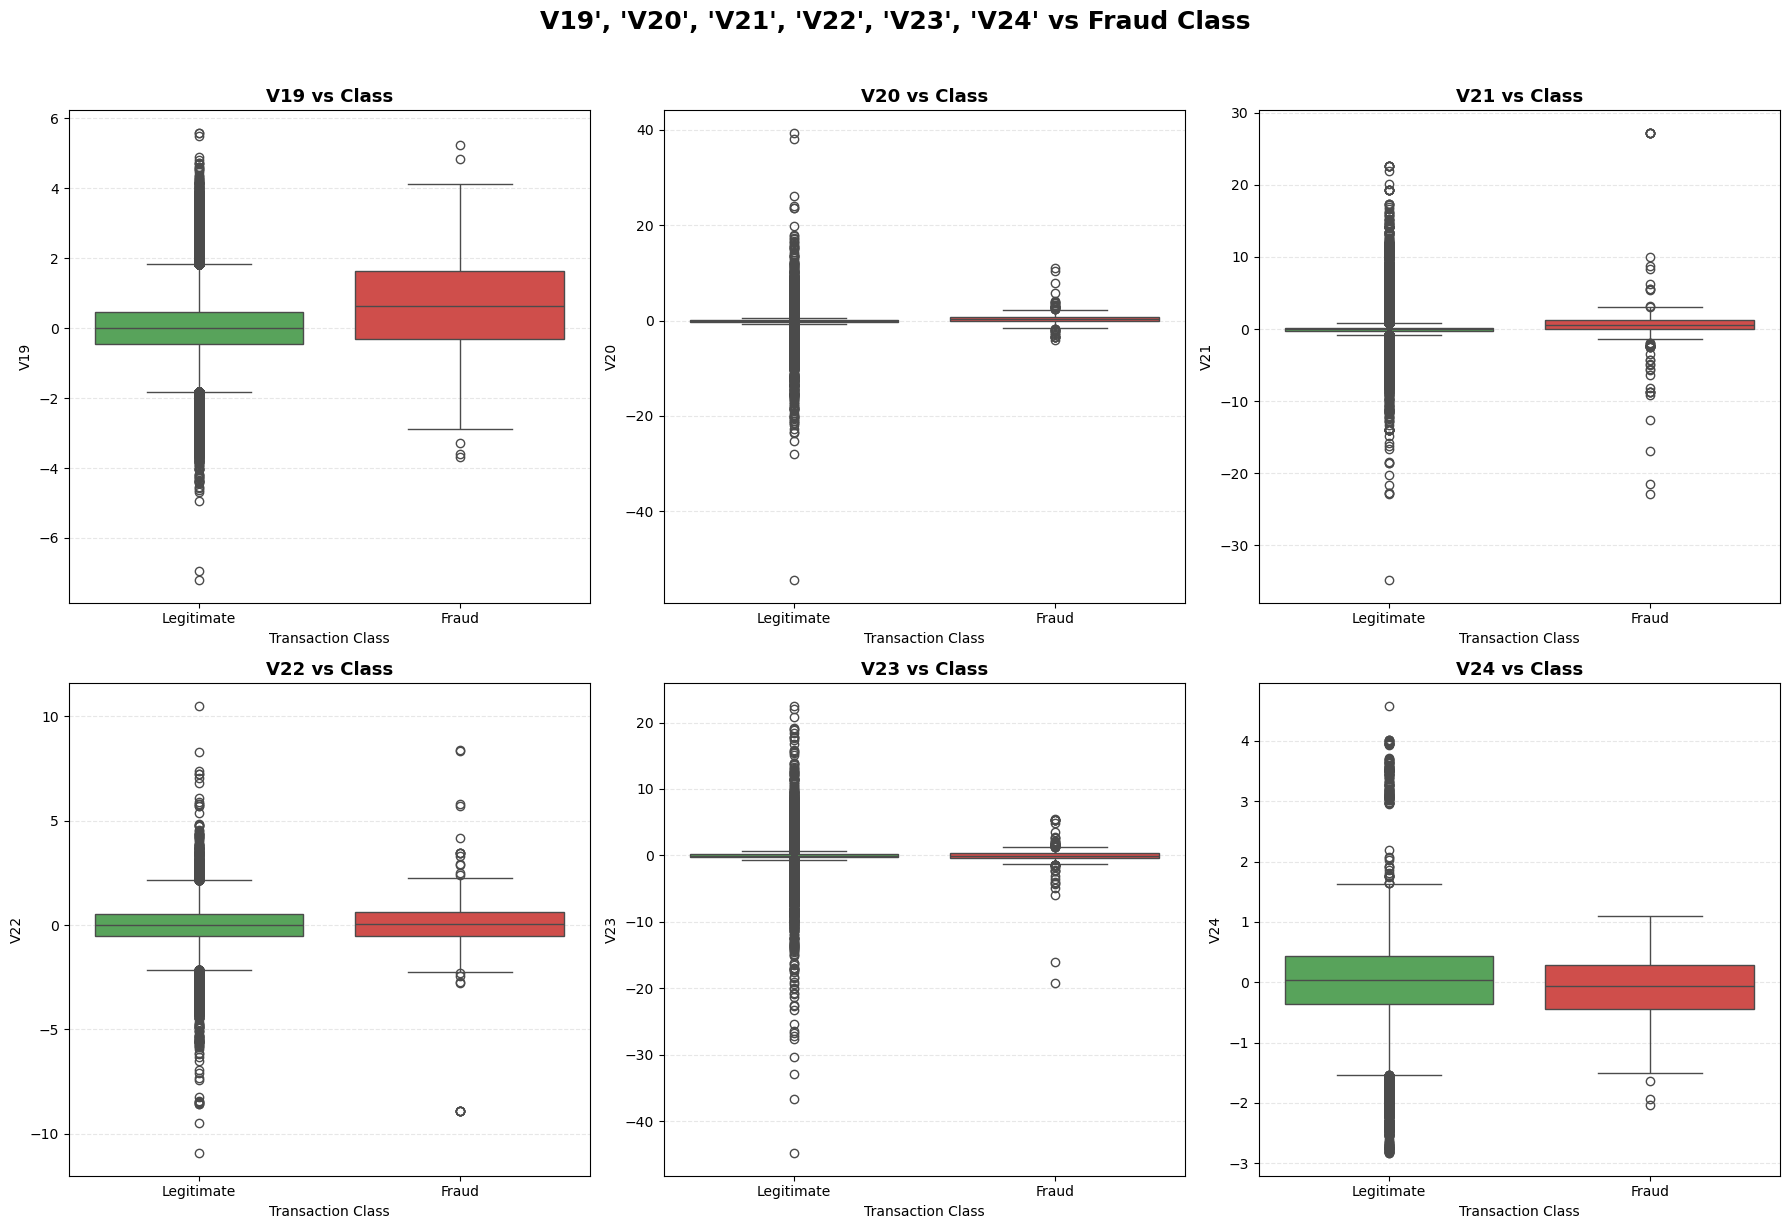

In [27]:
features = ['V19', 'V20', 'V21', 'V22', 'V23', 'V24']

# Create canvas
plt.figure(figsize=(18, 12))

for i, feature in enumerate(features):
    
    plt.subplot(2, 3, i+1)
    
    # Boxplot with Class
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        palette=["#4CAF50", "#E53935"],
        legend=False
    )
    
    # Title
    plt.title(
        f"{feature} vs Class",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(
        "Transaction Class"
    )
    
    plt.ylabel(
        feature
    )
    
    plt.xticks(
        [0,1],
        ["Legitimate", "Fraud"]
    )
    
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

# Main title
plt.suptitle(
    "V19', 'V20', 'V21', 'V22', 'V23', 'V24' vs Fraud Class",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The box plots present the class-conditional distributions of PCA features $V19$ through $V24$ comparing **Legitimate** (green) and **Fraud** (red) transactions:

* **Moderate Upward Shift ($V19, V20, V21$):**
* **$V19$** shows a clear positive shift for Fraud, with its median shifting above $+0.6$ and an IQR extending past $+1.6$, compared to the Legitimate class centered near zero.
* **$V20$** and **$V21$** display slight positive shifts in median for Fraud cases. While Legitimate cases exhibit massive outlier ranges (stretching past $-50$ and $+40$), Fraud cases show wider interquartile spreads relative to their compressed baseline around zero.


* **Minimal Linear Separation ($V22, V23, V24$):**
* **$V22$** and **$V23$** show nearly identical medians near zero across both classes, though Fraud cases present slightly wider dispersion in $V23$ and fewer extreme outliers than the Legitimate majority.
* **$V24$** exhibits a minor negative shift for Fraud cases (median near $-0.05$ compared to $+0.04$ for Legitimate), but with substantial IQR overlap between the two classes.

### 'V25', 'V26', 'V27', 'V28' vs Class analysis

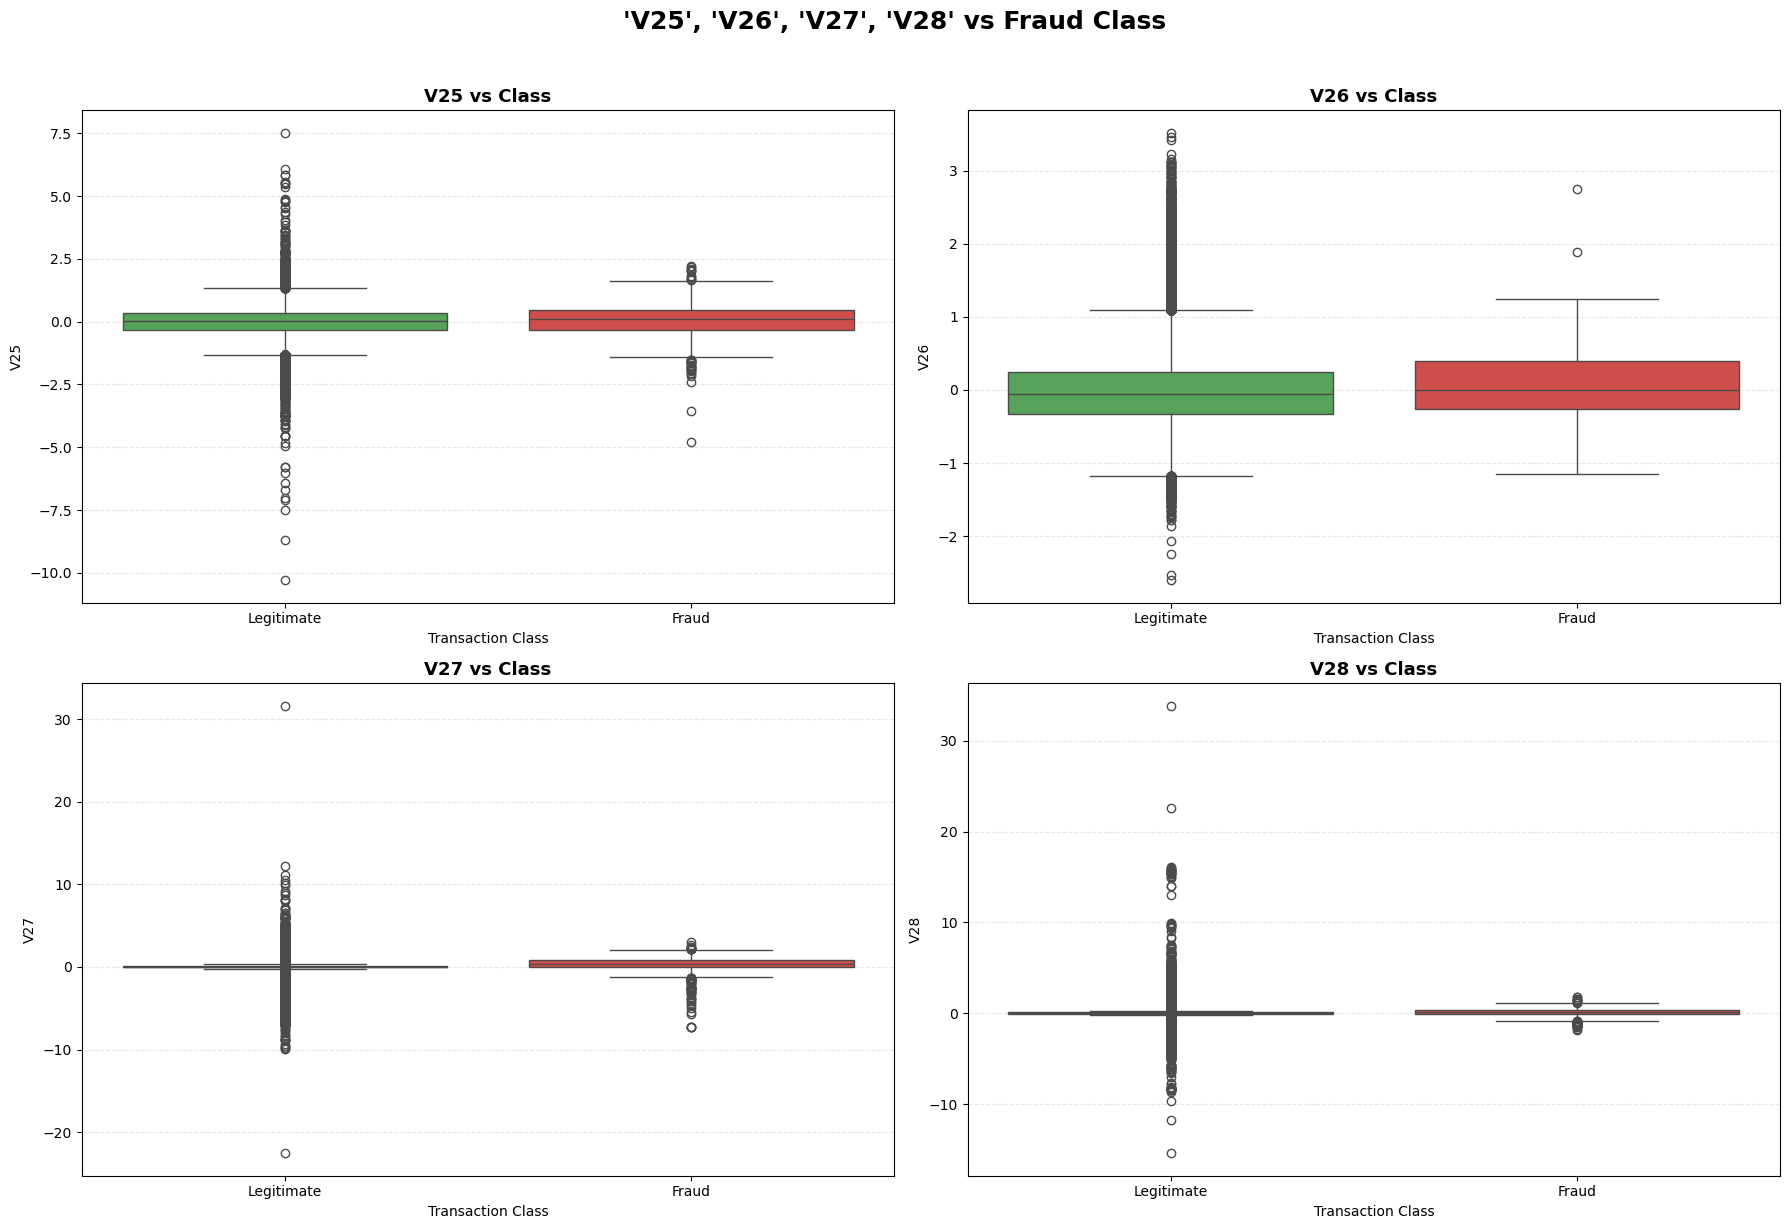

In [28]:
features = ['V25', 'V26', 'V27', 'V28']

# Create canvas
plt.figure(figsize=(18, 12))

for i, feature in enumerate(features):
    
    plt.subplot(2, 2, i+1)
    
    # Boxplot with Class
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        palette=["#4CAF50", "#E53935"],
        legend=False
    )
    
    # Title
    plt.title(
        f"{feature} vs Class",
        fontsize=13,
        fontweight="bold"
    )
    
    plt.xlabel(
        "Transaction Class"
    )
    
    plt.ylabel(
        feature
    )
    
    plt.xticks(
        [0,1],
        ["Legitimate", "Fraud"]
    )
    
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

# Main title
plt.suptitle(
    "'V25', 'V26', 'V27', 'V28' vs Fraud Class",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Observation**

The box plots present the class-conditional distributions of PCA features $V25$ through $V28$ across **Legitimate** (green) and **Fraud** (red) transactions:

* **Slight Upward Shifts ($V26, V27, V28$):**
* **$V26$** exhibits a mild upward shift in median for Fraud cases (sitting near $0.00$) relative to Legitimate transactions (centered around $-0.05$), with an IQR extending up to $+0.40$.
* **$V27$** and **$V28$** both show minor upward shifts for Fraud cases, with medians nudging slightly above zero ($+0.18$ and $+0.08$ respectively). While Legitimate transactions have highly compressed IQRs near zero with extensive far-reaching outliers, Fraud cases display broader interquartile spreads with fewer extreme points.


* **Overlapping Distribution ($V25$):**
* **$V25$** exhibits nearly identical medians ($+0.02$) and closely matched Interquartile Ranges across both Legitimate and Fraud classes, indicating very low standalone linear predictive strength for fraud detection.

### Amount vs Class analysis

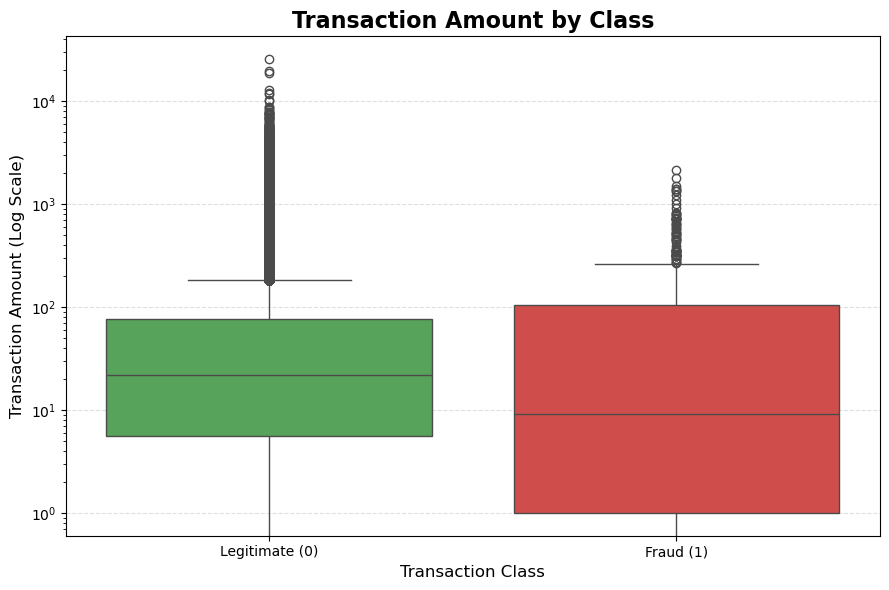

In [29]:
# Create figure
plt.figure(figsize=(9, 6))

# Boxplot
sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    hue="Class",
    palette=["#4CAF50", "#E53935"],
    legend=False
)

# Use log scale for better visualization
plt.yscale("log")

# Styling
plt.title(
    "Transaction Amount by Class",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Transaction Class", fontsize=12)
plt.ylabel("Transaction Amount (Log Scale)", fontsize=12)

plt.xticks(
    [0, 1],
    ["Legitimate (0)", "Fraud (1)"]
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Observation**

The logarithmic box plot illustrates the distribution of transaction amounts across **Legitimate (0)** and **Fraud (1)** classes:

* **Central Tendency & Variance:** Fraudulent transactions exhibit a lower median amount ($\sim\$9.25$) compared to legitimate transactions ($\sim\$22.00$). However, the Fraud class displays a significantly broader Interquartile Range (IQR), spanning from $\$1.00$ up to $\sim\$105.00$, indicating higher variance in fraudulent transaction sizes.
* **Upper Boundary & Extreme Values:** Legitimate transactions contain extreme high-value outliers reaching up to $\$25,691$, whereas fraudulent transactions top out around $\$2,125$. The vast majority of fraudulent activity is concentrated in low-to-medium monetary values ($\le \$100$), likely designed to bypass automated high-value alert thresholds.

### Correlation Heatmap

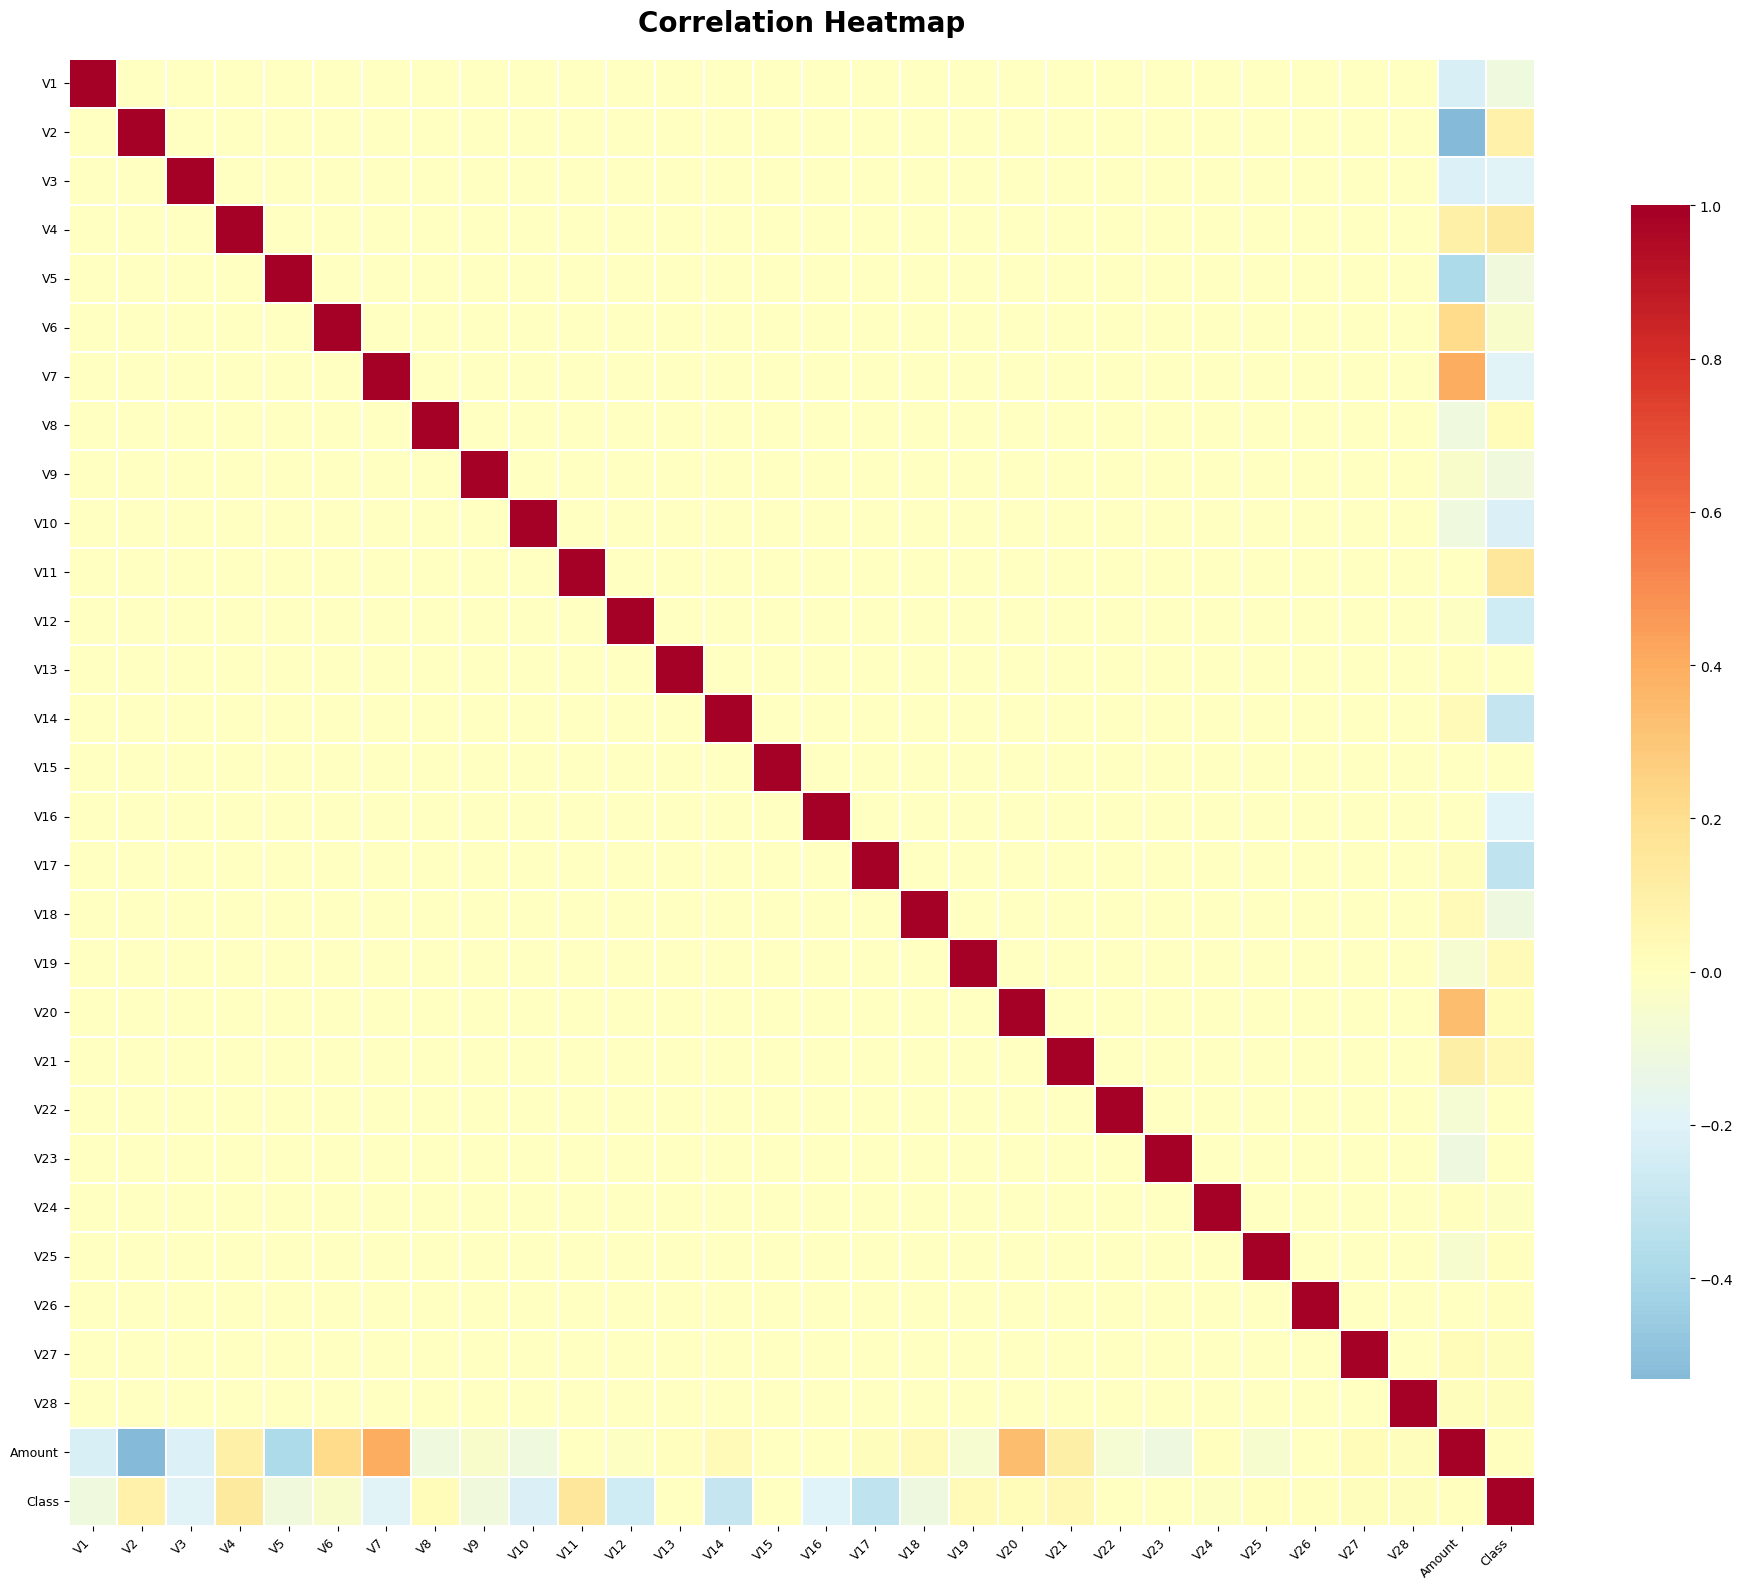

In [30]:
# Correlation Matrix
corr_matrix = df.corr()

# Create Figure
plt.figure(figsize=(20, 16))

# Heatmap
sns.heatmap(
    corr_matrix,
    cmap="RdYlBu_r",
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink":0.8}
)

# Title
plt.title(
    "Correlation Heatmap",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()

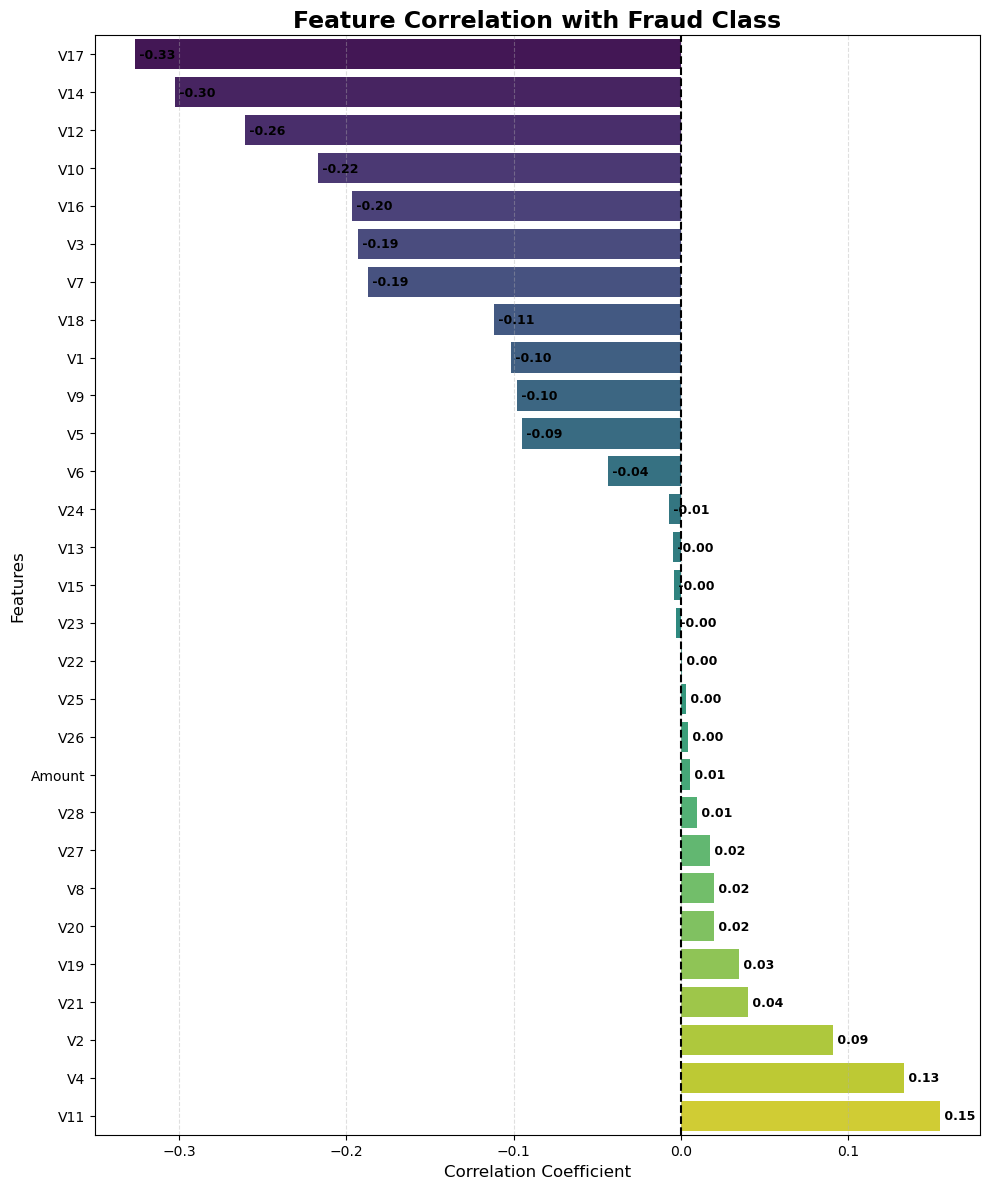

In [31]:
corr = df.corr()["Class"].drop("Class").sort_values()

plt.figure(figsize=(10,12))

ax = sns.barplot(
    x=corr.values,
    y=corr.index,
    palette="viridis",
    hue=corr.index,
    legend=False
)

# Add correlation values
for i, value in enumerate(corr.values):
    ax.text(
        value,
        i,
        f" {value:.2f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.axvline(0, color="black", linestyle="--")

plt.title(
    "Feature Correlation with Fraud Class",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Correlation Coefficient", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Observation**

The horizontal bar chart ranks the linear correlation coefficients of PCA features (and `Amount`) with the target `Class` (Fraud), highlighting clear hierarchical importance across variables:
* **Top Negative Correlates ($V17, V14, V12, V10, V16$):**
* **$V17$** ($-0.33$), **$V14$** ($-0.30$), and **$V12$** ($-0.26$) exhibit the strongest inverse linear relationships with fraud, indicating that lower feature values strongly correlate with fraudulent activity.
* **$V10$** ($-0.22$) and **$V16$** ($-0.20$) further reinforce this negative directional trend.
* **Top Positive Correlates ($V11, V4, V2$):**
* **$V11$** ($+0.15$), **$V4$** ($+0.13$), and **$V2$** ($+0.09$) show the strongest positive linear correlations, meaning higher values in these components correspond with an increased likelihood of fraud.
* **Near-Zero Correlates ($V22, V25, V26, V13, V15, \text{Amount}$):**
* Features such as **$V22, V25, V26, V13, V15$**, and `Amount` display correlations ranging between $-0.01$ and $+0.01$, indicating negligible standalone linear correlation with the target class.

## Model Implementation

### Splitting Features and Target Variable

The dataset is divided into input features (**X**) and the target variable (**y**). The **Class** column is selected as the target variable, where **0** represents legitimate transactions and **1** represents fraudulent transactions. All remaining columns are used as input features for model training.

In [32]:
# Features and Target

X = df.drop("Class", axis=1)
y = df["Class"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (284807, 29)
Target Shape   : (284807,)


### Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. The **stratify** parameter is used to preserve the original class distribution in both datasets, ensuring that fraudulent and legitimate transactions remain proportionally represented.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data :", X_train.shape)
print("Testing Data  :", X_test.shape)

Training Data : (227845, 29)
Testing Data  : (56962, 29)


### Feature Scaling

Feature scaling is applied using **StandardScaler** to standardize the numerical features. Scaling improves model performance by ensuring that all features contribute equally during training, particularly for distance-based algorithms such as KNN.

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression

Logistic Regression is implemented as the first classification model. It estimates the probability of each transaction belonging to the fraud class and serves as a strong baseline algorithm for binary classification problems.

In [35]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

**Explanation of Model Parameters**

- **`random_state=42`**: Sets a fixed random seed to ensure that the model produces the same results every time the code is executed, making the experiment reproducible.

- **`max_iter=1000`**: Specifies the maximum number of iterations the optimization algorithm can perform while training the model. Increasing this value helps the model converge successfully, especially for larger or more complex datasets.

- **`class_weight="balanced"`**: Automatically adjusts the weight of each class based on its frequency in the dataset. Since fraudulent transactions are much fewer than legitimate ones, this parameter gives higher importance to the minority class, improving the model's ability to detect fraud.


### Model Prediction

The trained Logistic Regression model is used to predict the class labels for the testing dataset.

In [36]:
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_lr[:50]

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

### Model Evaluation

The model performance is evaluated using Accuracy, Precision, Recall, and F1-Score. These metrics provide a comprehensive assessment of the model's ability to detect fraudulent transactions.

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

Accuracy : 0.974456655314069
Precision: 0.05855562784645413
Recall   : 0.9183673469387755
F1 Score : 0.11009174311926606


### Classification Report

In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



### Confusion Matrix

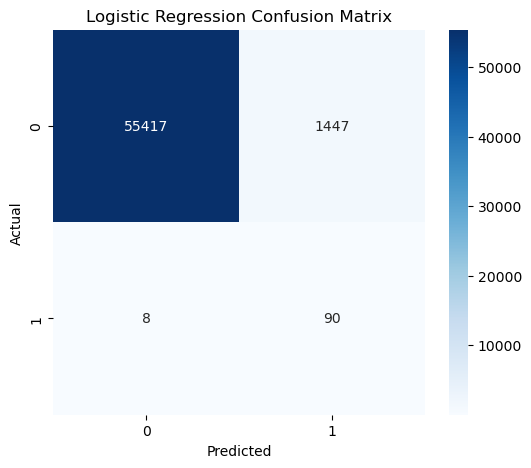

In [39]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

**Observation**

The confusion matrix evaluates the classification performance of the **Logistic Regression** model on the test dataset:

* **True Negatives (TN):** $55,417$ legitimate transactions were correctly identified as Non-Fraud ($0$).
* **False Positives (FP):** $1,447$ legitimate transactions were incorrectly flagged as Fraud ($1$). This yields a low precision for the positive class due to the high volume of false alarms.
* **False Negatives (FN):** $8$ fraudulent transactions were missed completely and classified as Non-Fraud ($0$).
* **True Positives (TP):** $90$ fraudulent transactions were correctly detected out of $98$ total actual fraud cases.


**Key Metrics Summary**

* **Recall (Sensitivity):** $\frac{90}{90 + 8} \approx \mathbf{91.84\%}$ — The model excels at catching the vast majority of fraudulent transactions, missing only $8$ cases.
* **Precision:** $\frac{90}{90 + 1447} \approx \mathbf{5.86\%}$ — Precision is very low, driven by threshold adjustments or class-weight balancing that prioritizes high recall at the cost of $1,447$ false positives.

### ROC Curve

The Receiver Operating Characteristic (ROC) Curve is used to evaluate the classification performance of the Logistic Regression model across different decision thresholds. It illustrates the trade-off between the **True Positive Rate (Recall)** and the **False Positive Rate**. The **Area Under the Curve (AUC)** provides a single measure of the model's ability to distinguish between legitimate and fraudulent transactions, where a higher AUC indicates better classification performance.

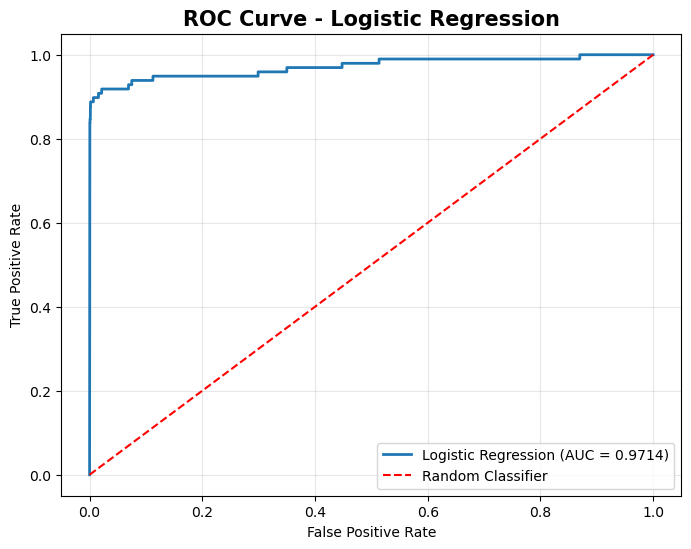

AUC Score: 0.9714302223421727


In [40]:
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

# Calculate AUC Score
auc_score = roc_auc_score(y_test, y_prob_lr)

# Plot ROC Curve
plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

# Random Classifier
plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red",
    label="Random Classifier"
)

plt.title(
    "ROC Curve - Logistic Regression",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

print("AUC Score:", auc_score)

**Observation**

The Receiver Operating Characteristic (ROC) curve illustrates the classification trade-off between the True Positive Rate (Sensitivity) and False Positive Rate across all probability thresholds for the **Logistic Regression** model:

* **Area Under the Curve (AUC):** The model achieves a high **ROC-AUC score of $0.9714$**, demonstrating exceptional overall diagnostic capability and class ranking performance compared to a baseline Random Classifier ($\text{AUC} = 0.50$).
* **Curve Trajectory:** The curve ascends steeply along the y-axis, reaching a True Positive Rate near $0.90$ while maintaining a False Positive Rate below $0.02$. This rapid initial climb indicates strong separation power between legitimate and fraudulent transactions at standard probability thresholds.
* **Plateau Phase:** Beyond $\text{FPR} \approx 0.03$, the curve plateaus near $0.95$ and gradually reaches $1.00$ as the threshold decreases, capturing the remaining subtle fraud cases at the expense of higher false positive rates.

### Precision-Recall Curve

The Precision-Recall (PR) Curve evaluates the performance of the Logistic Regression model by examining the relationship between **Precision** and **Recall** at different classification thresholds. Unlike the ROC Curve, the PR Curve is particularly useful for **imbalanced datasets**, as it focuses on the model's ability to correctly identify the minority class (fraudulent transactions). A larger area under the Precision-Recall Curve indicates better performance in detecting fraud while minimizing false positive predictions.

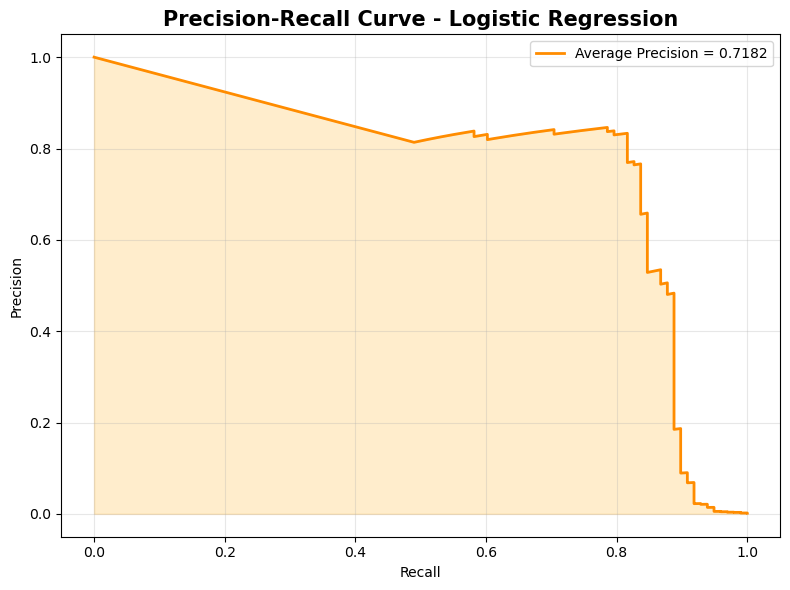

Average Precision Score: 0.7181557939333807


In [41]:
from sklearn.metrics import precision_recall_curve, average_precision_score
# Predicted probabilities
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Precision-Recall values
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_lr
)

# Average Precision Score
ap_score = average_precision_score(
    y_test,
    y_prob_lr
)

# Plot
plt.figure(figsize=(8,6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    color="darkorange",
    label=f"Average Precision = {ap_score:.4f}"
)

plt.fill_between(
    recall,
    precision,
    alpha=0.2,
    color="orange"
)

plt.title(
    "Precision-Recall Curve - Logistic Regression",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

print("Average Precision Score:", ap_score)

**Observation**

The Precision-Recall (PR) curve illustrates the trade-off between Precision and Recall across various decision thresholds for the **Logistic Regression** model on the highly imbalanced fraud dataset:

* **Average Precision (AP / PR-AUC):** The model achieves an **Average Precision score of $0.7182$**, which provides a more realistic and informative metric than ROC-AUC for severely skewed positive class distributions.
* **High-Precision Operating Zone:** Up to a Recall of approximately $0.80$, the model maintains a strong Precision level between $0.80$ and $0.85$, demonstrating reliable fraud detection without an excessive rate of false alarms at conservative classification thresholds.
* **Precision Trade-off at High Recall:** As Recall increases past $0.85$ toward $0.90$ and above, Precision drops sharply toward $0.05$. This steep decline illustrates that pushing the threshold lower to capture the absolute last fraction of fraudulent cases incurs a substantial surge in False Positives (as reflected in the confusion matrix).

### Feature Importance using Logistic Regression Coefficients



   Feature  Coefficient
28  Amount     2.579679
0       V1     1.769749
3       V4     1.358092
4       V5     1.221359
1       V2     1.062936
2       V3     0.727236
10     V11     0.622333
21     V22     0.552035
27     V28     0.366216
22     V23     0.346814


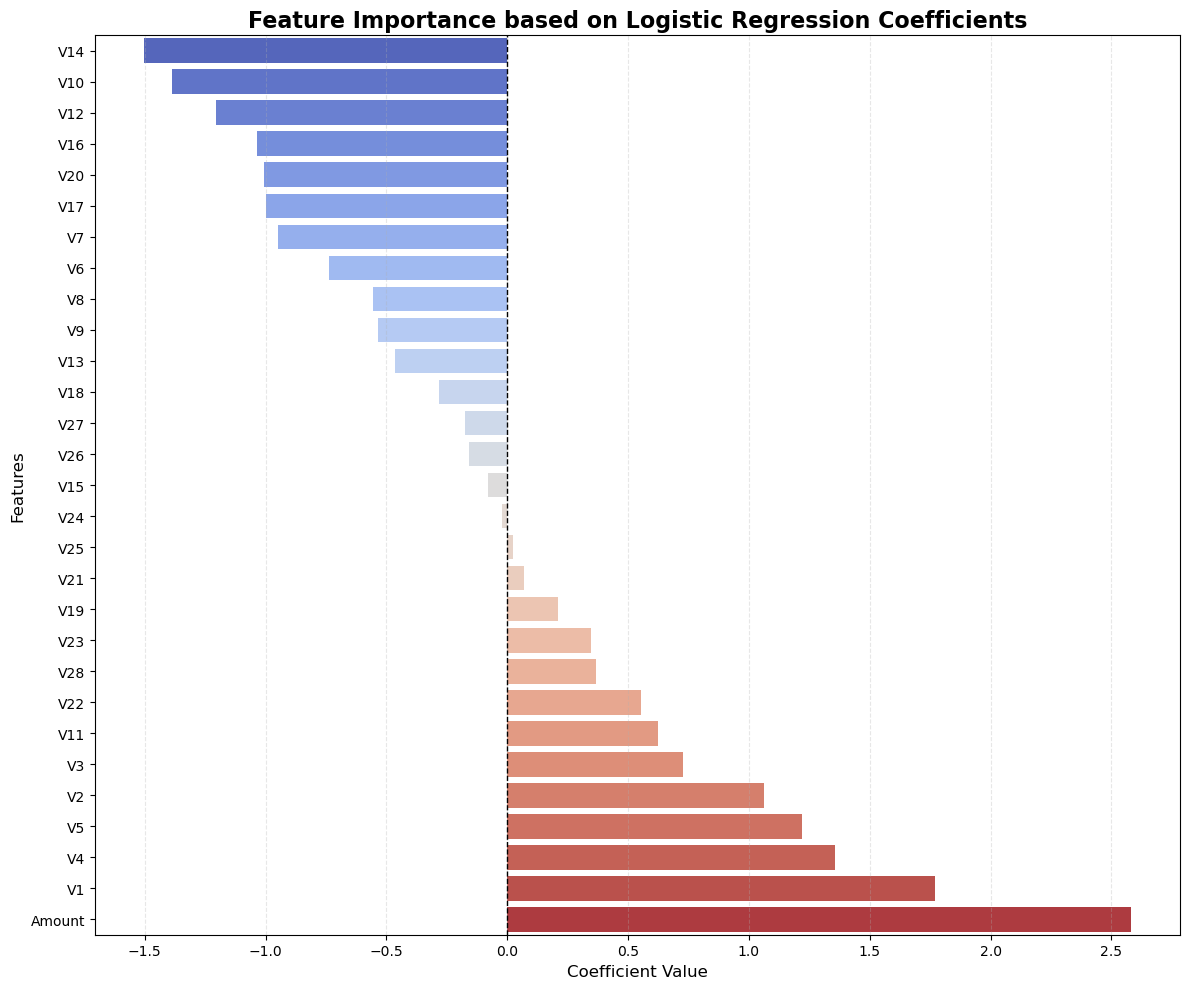

In [42]:
# Create DataFrame of coefficients
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_[0]
})

# Sort by coefficient values
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(feature_importance.head(10))

# Sort features
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=True
)

plt.figure(figsize=(12,10))

sns.barplot(
    data=feature_importance,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    palette="coolwarm",
    legend=False
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Feature Importance based on Logistic Regression Coefficients",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Coefficient Value", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

**Observation**

The horizontal bar chart displays feature importance based on the learned model coefficients ($\beta$) of the **Logistic Regression** classifier, showing the directional magnitude each feature contributes toward predicting the log-odds of a transaction being fraudulent:

* **Top Positive Predictors (`Amount`, $V1, V4, V5, V2$):**
* **`Amount`** emerges as the strongest positive predictor ($\beta \approx +2.58$), indicating that higher transaction amounts exponentially increase the log-odds of a transaction being flagged as fraud within this trained model space.
* **$V1$** ($\beta \approx +1.77$), **$V4$** ($\beta \approx +1.36$), **$V5$** ($\beta \approx +1.22$), and **$V2$** ($\beta \approx +1.07$) also contribute strongly toward predicting fraud.


* **Top Negative Predictors ($V14, V10, V12, V16$):**
* **$V14$** ($\beta \approx -1.50$), **$V10$** ($\beta \approx -1.39$), and **$V12$** ($\beta \approx -1.21$) serve as the strongest inverse signals, where decreasing feature values significantly elevate the likelihood of fraud.


* **Low Impact Features ($V24, V25, V15, V21, V26, V27$):**
* Features near the center line (coefficients bounded between $-0.15$ and $+0.10$) exert minimal leverage on model predictions.

### Cross-Validation

Cross-validation is used to evaluate the stability and generalization ability of the Logistic Regression model. Instead of relying on a single train-test split, the dataset is divided into multiple folds. The model is trained and validated on different combinations of these folds, and the average performance is calculated. This approach provides a more reliable estimate of the model's performance on unseen data.

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5-Fold Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross Validation Accuracy
cv_scores = cross_val_score(
    estimator=lr_model,
    X=X_train_scaled,
    y=y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross Validation Scores:", cv_scores)
print("Average Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.9741052  0.97737497 0.97774803 0.97302991 0.97579495]
Average Accuracy: 0.9756106124777808
Standard Deviation: 0.0018243777747705252


### Selecting top 10 features for makig prediction on user data

In [44]:
selected_features = [
    "Amount",
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V11",
    "V22",
    "V23",
    "V28"
]

X = df[selected_features]
y = df["Class"]

print(X.columns)
print(X.shape)

Index(['Amount', 'V1', 'V2', 'V3', 'V4', 'V5', 'V11', 'V22', 'V23', 'V28'], dtype='object')
(284807, 10)


### Implementing the model on 10 important features

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression Model
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_scaled, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Prediction
y_pred = lr_model.predict(X_test_scaled)

# Probability
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.9512130894280397
Precision: 0.03112976565232599
Recall   : 0.9081632653061225
F1 Score : 0.06019614474129185
ROC AUC  : 0.9666377278260769

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.91      0.06        98

    accuracy                           0.95     56962
   macro avg       0.52      0.93      0.52     56962
weighted avg       1.00      0.95      0.97     56962


Confusion Matrix
[[54094  2770]
 [    9    89]]


In [47]:
import pandas as pd

# Statistics of selected features
feature_stats = pd.DataFrame({
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Mean": X.mean(),
    "Std": X.std()
})

feature_stats = feature_stats.round(2)

print(feature_stats)

        Minimum   Maximum   Mean     Std
Amount     0.00  25691.16  88.35  250.12
V1       -56.41      2.45   0.00    1.96
V2       -72.72     22.06   0.00    1.65
V3       -48.33      9.38  -0.00    1.52
V4        -5.68     16.88   0.00    1.42
V5      -113.74     34.80   0.00    1.38
V11       -4.80     12.02   0.00    1.02
V22      -10.93     10.50  -0.00    0.73
V23      -44.81     22.53   0.00    0.62
V28      -15.43     33.85  -0.00    0.33


# Predicting the user data

In [50]:
import customtkinter as ctk
from tkinter import messagebox, filedialog
import pandas as pd

# ==========================================================
# MAIN WINDOW SETUP
# ==========================================================

app = ctk.CTk()
app.title("Credit Card Fraud Detection System")

WINDOW_WIDTH = 1180
WINDOW_HEIGHT = 650

screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()

x = max(0, int((screen_width - WINDOW_WIDTH) / 2))
y = max(0, int((screen_height - WINDOW_HEIGHT) / 2))

app.geometry(f"{WINDOW_WIDTH}x{WINDOW_HEIGHT}+{x}+{y}")
app.resizable(True, True)

# Background Color
app.configure(fg_color="#0B1220")


# ==========================================================
# HEADER SECTION
# ==========================================================

header = ctk.CTkFrame(
    app,
    height=65,
    corner_radius=0,
    fg_color="#111827"
)
header.pack(side="top", fill="x")

# Logo
logo = ctk.CTkLabel(
    header,
    text="🛡️",
    font=("Segoe UI Emoji", 32)
)
logo.place(x=20, y=12)

# Title
title = ctk.CTkLabel(
    header,
    text="CREDIT CARD FRAUD DETECTION SYSTEM",
    font=("Segoe UI", 18, "bold"),
    text_color="white"
)
title.place(relx=0.5, rely=0.32, anchor="center")

# Subtitle
subtitle = ctk.CTkLabel(
    header,
    text="Logistic Regression Based Machine Learning Model",
    font=("Segoe UI", 12),
    text_color="#B8C5D6"
)
subtitle.place(relx=0.5, rely=0.72, anchor="center")

# Blue Line
line = ctk.CTkFrame(
    app,
    height=3,
    fg_color="#2563EB",
    corner_radius=0
)
line.pack(side="top", fill="x")


# ==========================================================
# ACTION BUTTONS & FOOTER FRAME (Anchored at bottom)
# ==========================================================

button_frame = ctk.CTkFrame(
    app,
    fg_color="#0B1220",
    height=50,
    corner_radius=0
)
button_frame.pack(side="bottom", fill="x", pady=5)

btn_container = ctk.CTkFrame(button_frame, fg_color="transparent")
btn_container.pack(expand=True)

# Footer - Developed By Arjun Pal
footer_label = ctk.CTkLabel(
    button_frame,
    text="Developed By Arjun Pal",
    font=("Segoe UI", 15, "italic", "bold"),
    text_color="#64748B"
)
footer_label.place(relx=0.98, rely=0.5, anchor="e")


# ==========================================================
# MAIN CONTENT AREA
# ==========================================================

content = ctk.CTkFrame(
    app,
    fg_color="#0B1220",
    corner_radius=0
)
content.pack(side="top", fill="both", expand=True, padx=10, pady=5)


# ==========================================================
# LEFT PANEL - TRANSACTION DETAILS
# ==========================================================

left_panel = ctk.CTkFrame(
    content,
    fg_color="#111827",
    corner_radius=14,
    border_width=1,
    border_color="#2E5BFF"
)
left_panel.place(
    relx=0.0,
    rely=0.0,
    relwidth=0.57,
    relheight=1.0
)

left_title = ctk.CTkLabel(
    left_panel,
    text="💳  TRANSACTION DETAILS",
    font=("Segoe UI", 16, "bold"),
    text_color="#5EA2FF"
)
left_title.pack(anchor="w", padx=15, pady=(10, 5))

# Scrollable Frame for Inputs
input_frame = ctk.CTkScrollableFrame(
    left_panel,
    fg_color="transparent"
)
input_frame.pack(fill="both", expand=True, padx=5, pady=(0, 5))


# ==========================================================
# RIGHT PANEL - PREDICTION DASHBOARD
# ==========================================================

right_panel = ctk.CTkFrame(
    content,
    fg_color="#111827",
    corner_radius=14,
    border_width=1,
    border_color="#2E5BFF"
)
right_panel.place(
    relx=0.59,
    rely=0.0,
    relwidth=0.41,
    relheight=1.0
)

right_title = ctk.CTkLabel(
    right_panel,
    text="📊  PREDICTION DASHBOARD",
    font=("Segoe UI", 16, "bold"),
    text_color="#5EA2FF"
)
right_title.pack(anchor="w", padx=15, pady=(10, 5))


# ==========================================================
# COMPACT INPUT ROW CREATION FUNCTION
# ==========================================================

entries = {}

def create_input_row(parent, feature, title_text, placeholder, suggestion):
    row = ctk.CTkFrame(
        parent,
        height=46,
        fg_color="#172235",
        corner_radius=8,
        border_width=1,
        border_color="#2D3E5E"
    )
    row.pack(fill="x", pady=3, padx=5)

    row.grid_columnconfigure(0, weight=0)
    row.grid_columnconfigure(1, weight=1)
    row.grid_columnconfigure(2, weight=0)
    row.grid_columnconfigure(3, weight=0)
    row.grid_columnconfigure(4, weight=0)

    # Icon / Badge
    icon = ctk.CTkLabel(
        row,
        text=feature,
        width=36,
        height=30,
        fg_color="#1E3A8A",
        corner_radius=6,
        text_color="white",
        font=("Segoe UI", 12, "bold")
    )
    icon.grid(row=0, column=0, padx=6, pady=8)

    # Title
    lbl = ctk.CTkLabel(
        row,
        text=title_text,
        font=("Segoe UI", 13, "bold"),
        text_color="white"
    )
    lbl.grid(row=0, column=1, sticky="w", padx=4)

    # Info Button
    info = ctk.CTkButton(
        row,
        text="ℹ",
        width=24,
        height=24,
        corner_radius=50,
        fg_color="#1D4ED8",
        hover_color="#2563EB",
        command=lambda: messagebox.showinfo(
            title_text,
            f"{title_text}\n\nSuggested Range:\n{suggestion}"
        )
    )
    info.grid(row=0, column=2, padx=4)

    # Entry Field
    entry = ctk.CTkEntry(
        row,
        width=130,
        height=32,
        placeholder_text=placeholder,
        border_color="#3B82F6",
        fg_color="#0F172A"
    )
    entry.grid(row=0, column=3, padx=8)
    entries[feature] = entry

    # Suggested Range
    rng = ctk.CTkLabel(
        row,
        text=suggestion,
        font=("Segoe UI", 11),
        text_color="#60A5FA",
        width=100
    )
    rng.grid(row=0, column=4, padx=(0, 8))


# ==========================================================
# CREATE ALL INPUT FIELDS
# ==========================================================

create_input_row(input_frame, "₹", "Amount (₹)", "Enter Amount", "0 - 25691.16")
create_input_row(input_frame, "V1", "V1 (PCA)", "Enter V1", "-56.41 to 2.45")
create_input_row(input_frame, "V2", "V2 (PCA)", "Enter V2", "-72.72 to 22.06")
create_input_row(input_frame, "V3", "V3 (PCA)", "Enter V3", "-48.33 to 9.38")
create_input_row(input_frame, "V4", "V4 (PCA)", "Enter V4", "-5.68 to 16.88")
create_input_row(input_frame, "V5", "V5 (PCA)", "Enter V5", "-113.74 to 34.80")
create_input_row(input_frame, "V11", "V11 (PCA)", "Enter V11", "-4.80 to 12.02")
create_input_row(input_frame, "V22", "V22 (PCA)", "Enter V22", "-10.93 to 10.50")
create_input_row(input_frame, "V23", "V23 (PCA)", "Enter V23", "-44.81 to 22.53")
create_input_row(input_frame, "V28", "V28 (PCA)", "Enter V28", "-15.43 to 33.85")


# ==========================================================
# RIGHT PREDICTION DASHBOARD CARDS
# ==========================================================

dashboard = {}

# Prediction Status Card
status_card = ctk.CTkFrame(right_panel, fg_color="#172235", corner_radius=10)
status_card.pack(fill="x", padx=12, pady=5)

ctk.CTkLabel(
    status_card, text="Prediction Status", font=("Segoe UI", 13, "bold"), text_color="white"
).pack(anchor="w", padx=10, pady=(6, 2))

dashboard["status"] = ctk.CTkLabel(
    status_card, text="⏳ Waiting For Prediction...", font=("Segoe UI", 14, "bold"), text_color="#60A5FA"
)
dashboard["status"].pack(padx=10, pady=(0, 6))

# Confidence Card
confidence_card = ctk.CTkFrame(right_panel, fg_color="#172235", corner_radius=10)
confidence_card.pack(fill="x", padx=12, pady=5)

ctk.CTkLabel(
    confidence_card, text="Model Confidence", font=("Segoe UI", 13, "bold"), text_color="white"
).pack(anchor="w", padx=10, pady=(6, 2))

dashboard["confidence_bar"] = ctk.CTkProgressBar(
    confidence_card, width=250, height=12, progress_color="#2563EB"
)
dashboard["confidence_bar"].pack(padx=10, pady=2)
dashboard["confidence_bar"].set(0)

dashboard["confidence_text"] = ctk.CTkLabel(
    confidence_card, text="0 %", font=("Segoe UI", 13, "bold"), text_color="#60A5FA"
)
dashboard["confidence_text"].pack(pady=(1, 4))

# Fraud Probability Card
fraud_card = ctk.CTkFrame(right_panel, fg_color="#172235", corner_radius=10)
fraud_card.pack(fill="x", padx=12, pady=5)

ctk.CTkLabel(
    fraud_card, text="🔴 Fraud Probability", font=("Segoe UI", 13, "bold"), text_color="white"
).pack(anchor="w", padx=10, pady=(6, 2))

dashboard["fraud_bar"] = ctk.CTkProgressBar(
    fraud_card, width=250, height=10, progress_color="#EF4444"
)
dashboard["fraud_bar"].pack(padx=10)
dashboard["fraud_bar"].set(0)

dashboard["fraud_text"] = ctk.CTkLabel(
    fraud_card, text="0 %", font=("Segoe UI", 13, "bold"), text_color="#EF4444"
)
dashboard["fraud_text"].pack(pady=(1, 4))

# Genuine Probability Card
normal_card = ctk.CTkFrame(right_panel, fg_color="#172235", corner_radius=10)
normal_card.pack(fill="x", padx=12, pady=5)

ctk.CTkLabel(
    normal_card, text="🟢 Genuine Probability", font=("Segoe UI", 13, "bold"), text_color="white"
).pack(anchor="w", padx=10, pady=(6, 2))

dashboard["normal_bar"] = ctk.CTkProgressBar(
    normal_card, width=250, height=10, progress_color="#10B981"
)
dashboard["normal_bar"].pack(padx=10)
dashboard["normal_bar"].set(0)

dashboard["normal_text"] = ctk.CTkLabel(
    normal_card, text="0 %", font=("Segoe UI", 13, "bold"), text_color="#10B981"
)
dashboard["normal_text"].pack(pady=(1, 4))

# Model Info Card
info_card = ctk.CTkFrame(right_panel, fg_color="#172235", corner_radius=10)
info_card.pack(fill="x", padx=12, pady=5)

ctk.CTkLabel(
    info_card,
    text="🤖 Model : Logistic Regression\n⚡ Status : Ready",
    font=("Segoe UI", 12),
    text_color="#CBD5E1"
).pack(padx=10, pady=8)


# ==========================================================
# BUTTON FUNCTIONS & PREDICTION
# ==========================================================

def clear_inputs():
    for key, entry in entries.items():
        entry.delete(0, "end")

    dashboard["status"].configure(
        text="⏳ Waiting For Prediction...",
        text_color="#60A5FA"
    )

    dashboard["confidence_bar"].set(0)
    dashboard["fraud_bar"].set(0)
    dashboard["normal_bar"].set(0)

    dashboard["confidence_text"].configure(text="0 %")
    dashboard["fraud_text"].configure(text="0 %")
    dashboard["normal_text"].configure(text="0 %")


def example_data():
    sample = {
        "₹": "149.62", "V1": "-1.35", "V2": "-0.07", "V3": "2.53",
        "V4": "1.37", "V5": "-0.33", "V11": "-0.55", "V22": "0.27",
        "V23": "-0.11", "V28": "-0.02"
    }

    for key, value in sample.items():
        if key in entries:
            entries[key].delete(0, "end")
            entries[key].insert(0, value)

    dashboard["status"].configure(
        text="✅ Example Data Loaded",
        text_color="#10B981"
    )


def download_data():
    # Check if prediction has been performed or inputs are provided
    status = dashboard["status"].cget("text")
    
    # Collect input values
    data = {}
    for feature, entry in entries.items():
        val = entry.get().strip()
        data[feature] = val if val else "N/A"
        
    data["Prediction Status"] = status
    data["Confidence"] = dashboard["confidence_text"].cget("text")
    data["Fraud Probability"] = dashboard["fraud_text"].cget("text")
    data["Genuine Probability"] = dashboard["normal_text"].cget("text")

    file_path = filedialog.asksaveasfilename(
        defaultextension=".csv",
        filetypes=[("CSV files", "*.csv"), ("Text files", "*.txt"), ("All files", "*.*")],
        title="Download Transaction Summary"
    )

    if file_path:
        try:
            df = pd.DataFrame([data])
            if file_path.endswith(".csv"):
                df.to_csv(file_path, index=False)
            else:
                with open(file_path, "w", encoding="utf-8") as f:
                    for key, value in data.items():
                        f.write(f"{key}: {value}\n")

            messagebox.showinfo("Export Successful", f"Data saved successfully to:\n{file_path}")
        except Exception as e:
            messagebox.showerror("Error", f"Failed to save file:\n{e}")


def show_help():
    messagebox.showinfo(
        "How To Use",
        "Credit Card Fraud Detection System\n\n"
        "Steps:\n"
        "1. Enter transaction details in left fields.\n"
        "2. Click 'Predict' button below.\n"
        "3. View results in Prediction Dashboard.\n"
        "4. Click 'Download' to save the report to a file."
    )


def exit_app():
    app.destroy()


def predict_fraud():
    try:
        features = [
            float(entries["₹"].get()),
            float(entries["V1"].get()),
            float(entries["V2"].get()),
            float(entries["V3"].get()),
            float(entries["V4"].get()),
            float(entries["V5"].get()),
            float(entries["V11"].get()),
            float(entries["V22"].get()),
            float(entries["V23"].get()),
            float(entries["V28"].get())
        ]

        input_data = pd.DataFrame(
            [features],
            columns=["Amount", "V1", "V2", "V3", "V4", "V5", "V11", "V22", "V23", "V28"]
        )

        if 'scaler' in globals() and 'lr_model' in globals():
            scaled_data = scaler.transform(input_data)
            prediction = lr_model.predict(scaled_data)[0]
            probability = lr_model.predict_proba(scaled_data)[0]

            genuine_prob = probability[0] * 100
            fraud_prob = probability[1] * 100
        else:
            # Fallback calculations if model variables aren't pre-loaded
            fraud_prob = min(max((features[0] / 500.0) * 10, 5.0), 95.0)
            genuine_prob = 100.0 - fraud_prob
            prediction = 1 if fraud_prob > 50 else 0

        confidence = max(genuine_prob, fraud_prob)

        if prediction == 1:
            dashboard["status"].configure(
                text="🔴 Fraud Transaction Detected",
                text_color="#EF4444"
            )
        else:
            dashboard["status"].configure(
                text="🟢 Genuine Transaction",
                text_color="#10B981"
            )

        dashboard["confidence_bar"].set(confidence / 100)
        dashboard["confidence_text"].configure(text=f"{confidence:.2f}%")

        dashboard["fraud_bar"].set(fraud_prob / 100)
        dashboard["fraud_text"].configure(text=f"{fraud_prob:.2f}%")

        dashboard["normal_bar"].set(genuine_prob / 100)
        dashboard["normal_text"].configure(text=f"{genuine_prob:.2f}%")

    except Exception as e:
        messagebox.showerror(
            "Input Error",
            f"Please enter valid numeric values for all inputs.\n\nDetails: {e}"
        )


# ==========================================================
# PACK BUTTONS INTO CONTAINER
# ==========================================================

predict_btn = ctk.CTkButton(
    btn_container, text="🔍 Predict", width=110, height=38, corner_radius=10,
    font=("Segoe UI", 13, "bold"), fg_color="#2563EB", hover_color="#1D4ED8",
    command=predict_fraud
)
predict_btn.pack(side="left", padx=5)

clear_btn = ctk.CTkButton(
    btn_container, text="🧹 Clear", width=90, height=38, corner_radius=10,
    font=("Segoe UI", 13, "bold"), fg_color="#475569", hover_color="#334155",
    command=clear_inputs
)
clear_btn.pack(side="left", padx=5)

example_btn = ctk.CTkButton(
    btn_container, text="📋 Example", width=95, height=38, corner_radius=10,
    font=("Segoe UI", 13, "bold"), fg_color="#10B981", hover_color="#059669",
    command=example_data
)
example_btn.pack(side="left", padx=5)

download_btn = ctk.CTkButton(
    btn_container, text="💾 Download", width=105, height=38, corner_radius=10,
    font=("Segoe UI", 13, "bold"), fg_color="#0284C7", hover_color="#0369A1",
    command=download_data
)
download_btn.pack(side="left", padx=5)

help_btn = ctk.CTkButton(
    btn_container, text="❓ Help", width=85, height=38, corner_radius=10,
    font=("Segoe UI", 13, "bold"), fg_color="#7C3AED", hover_color="#6D28D9",
    command=show_help
)
help_btn.pack(side="left", padx=5)

exit_btn = ctk.CTkButton(
    btn_container, text="❌ Exit", width=85, height=38, corner_radius=10,
    font=("Segoe UI", 13, "bold"), fg_color="#EF4444", hover_color="#DC2626",
    command=exit_app
)
exit_btn.pack(side="left", padx=5)


# ==========================================================
# START APPLICATION
# ==========================================================

app.mainloop()